# Clasificar series temporale: GDG UAM ML Contest

**Problema.** Cada muestra son 4 canales × 256 pasos de tiempo (con huecos `NaN`) y tres metadatos (`sample_rate`, `group`, `level`). Hay que decir a cuál de 8 clases pertenece. El modelo recibe **una muestra por llamada**, en **1 hilo de CPU**, y se puntúa cuántas muestras responde bien en **60 s** de tiempo de `predict`.

**Métrica.** $\text{Score}=\big(\prod_{k=0}^{7}T_k\big)^{1/8}$ con $T_k=\max\!\big(0.01,\;\sqrt{n_k}\cdot\frac{c_k-0.33\,w_k}{n_k}\cdot(c_k/n_k)^2\big)$. Es una media geométrica: **la peor clase manda**. El acierto pesa casi al cubo y la velocidad como raíz cuadrada.

**Para ejecutarlo:** hay que tener `data/train_100k.npz` y `data/test_demo.npz`; si no están, la celda siguiente los descarga de la *release* oficial. Dependencias en `requirements-notebook.txt`. La Fase 4 usa el harness oficial. 

**Tiempo de ejecución completo: ~40–50 min** 

**Resultado.** El número final está al final y en `resultados.json`.

In [1]:
import time, warnings
from pathlib import Path
T_INICIO = time.time()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

import procesado as pp   # el preprocesado que también usa model.py

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 3)
np.set_printoptions(precision=3, suppress=True, linewidth=180)
SEMILLA, K = 0, 8
CLASES = list(range(K))

# Paleta de los gráficos (validada para daltonismo en fondo claro y oscuro; sin azul)
C_TRAIN, C_DEMO = "#1baf7a", "#eb6834"      # aqua = train, naranja = demo (test)
C_A, C_B = "#008300", "#e87ba4"             # verde / magenta: comparar dos clases
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2, "text.color": TINTA,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False, "lines.linewidth": 1.6,
})


def buscar_datos() -> Path:
    for base in (Path("data"), Path("../data")):
        if (base / "train_100k.npz").exists() and (base / "test_demo.npz").exists():
            return base
    import urllib.request
    base = Path("data"); base.mkdir(exist_ok=True)
    url = "https://github.com/GDG-UAM/ml-contest-materials/releases/latest/download/"
    for f in ("train_100k.npz", "test_demo.npz"):
        print("descargando", f, "...")
        urllib.request.urlretrieve(url + f, base / f)
    return base


def cargar(path: Path) -> dict:
    z = np.load(path, allow_pickle=False)
    return dict(X=z["series"], y=z["labels"].astype(int), g=z["meta__group"].astype(str),
                sr=z["meta__sample_rate"].astype(float), lv=z["meta__level"].astype(float))


DATOS = buscar_datos()
t0 = time.time()
TR, DE = cargar(DATOS / "train_100k.npz"), cargar(DATOS / "test_demo.npz")
print(f"datos: {DATOS.resolve()}  | cargados en {time.time() - t0:.1f} s")
print("train:", TR["X"].shape, TR["X"].dtype, "| demo:", DE["X"].shape, DE["X"].dtype)

datos: C:\Users\ruben\Documents\GDG\ML_contest\data  | cargados en 4.6 s
train: (100000, 4, 256) float32 | demo: (400, 4, 256) float32


---
# Fase 1. Entender y analizar los datos

Antes de tocar un modelo hay que saber **cómo son los datos, cómo se construyó el fichero, qué distingue a cada clase y en qué se diferencia el test del train**. No asumimos nada: todo se mide. El test real no lo vemos nunca; su representante es `test_demo` (400 muestras "generadas como las del test").

Regla de lectura de toda la fase: con 400 muestras de demo (50 por clase) hay ruido estadístico. Para cada diferencia nos preguntamos si es **real** (mucho mayor que el ruido) o **casual**.

## 1.1 Estructura: formas, tipos, rangos y huecos

In [2]:
def resumen(D, nombre):
    X = D["X"]; nan = np.isnan(X)
    return {"conjunto": nombre, "muestras": X.shape[0], "canales × pasos": f"{X.shape[1]} × {X.shape[2]}",
            "tipo": str(X.dtype), "mín": float(np.nanmin(X)), "máx": float(np.nanmax(X)),
            "máx |x|": float(np.nanmax(np.abs(X))), "% valores NaN": 100 * nan.mean(),
            "% muestras sin NaN": 100 * (~nan.any(axis=(1, 2))).mean(), "valores inf": int(np.isinf(X).sum())}

display(pd.DataFrame([resumen(TR, "train"), resumen(DE, "demo")]).set_index("conjunto"))
print("metadatos:", {k: (TR[k].dtype, np.unique(TR[k])[:4] if k in ("g", "sr") else (TR[k].min().round(2), TR[k].max().round(2)))
                     for k in ("g", "sr", "lv")})

,muestras,canales × pasos,tipo,mín,máx,máx |x|,% valores NaN,% muestras sin NaN,valores inf
conjunto,,,,,,,,,
train,100000,4 × 256,float32,-70.525,67.290,70.525,0.726,8.578,0
demo,400,4 × 256,float32,-1677.772,601.168,1677.772,1.380,0.750,0


metadatos: {'g': (dtype('<U1'), array(['A', 'B', 'C'], dtype='<U1')), 'sr': (dtype('float64'), array([1., 2.])), 'lv': (dtype('float64'), (np.float64(-4.0), np.float64(4.0)))}


**Lectura.** El train son 100 000 muestras de 4 canales × 256 pasos en `float32`; el demo, 400 con la misma forma. Ya se ven dos diferencias: **(1)** el demo tiene casi el doble de huecos (0.73 % → 1.38 % de los valores; solo el 0.75 % de sus muestras está completa, frente al 8.6 % del train) y **(2)** valores enormes: en train |x| ≤ 70.5 y en demo llega a 1678. No hay `inf`. Metadatos: `group` es texto (A/B/C), `sample_rate` vale 1 o 2 y `level` es continuo en [−4, 4].
→ *Consecuencia:* `predict` tiene que tolerar más NaN que en el entrenamiento y valores extremos sin romperse.

## 1.2 ¿Cómo se construyó el fichero? (orden de las filas)

**Por qué importa.** Si el fichero viene ordenado, coger "las primeras 20 000 filas" para validar no es una muestra aleatoria: la validación mentiría.

train: la etiqueta cambia 7 veces en 100000 filas; la clase k empieza en la fila [0, 15993, 30020, 43957, 55872, 67852, 80012, 90135]
train[:20000] contiene las clases [0, 1]  ← una 'muestra' así no sirve para validar
demo: 80 rachas de la misma clase, longitud media 5.0


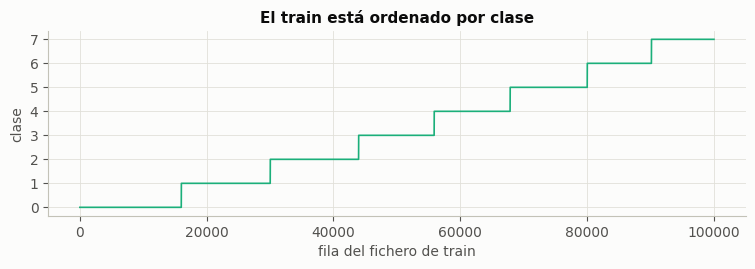

In [3]:
cambios = int((np.diff(TR["y"]) != 0).sum())
inicio = [int(np.flatnonzero(TR["y"] == k)[0]) for k in CLASES]
rachas_demo = np.diff(np.flatnonzero(np.r_[True, np.diff(DE["y"]) != 0, True]))
print(f"train: la etiqueta cambia {cambios} veces en {len(TR['y'])} filas; la clase k empieza en la fila {inicio}")
print(f"train[:20000] contiene las clases {np.unique(TR['y'][:20000]).tolist()}  ← una 'muestra' así no sirve para validar")
print(f"demo: {len(rachas_demo)} rachas de la misma clase, longitud media {rachas_demo.mean():.1f}")

fig, ax = plt.subplots(figsize=(9, 2.4))
ax.plot(TR["y"], color=C_TRAIN, lw=1.2)
ax.set(xlabel="fila del fichero de train", ylabel="clase", title="El train está ordenado por clase", yticks=CLASES)
plt.show()

**Lectura.** La etiqueta cambia solo **7 veces** en 100 000 filas: el train está **ordenado por clase** (bloques 0, 1, …, 7). Coger las primeras 20 000 filas daría solo las clases 0 y 1. El demo viene en rachas de unas 5 muestras de la misma clase.
→ *Decisión:* toda validación se hace con **muestreo aleatorio estratificado** y semilla fija; nunca `[:n]`.

## 1.3 Balance de clases

In [4]:
bal = pd.DataFrame({"train (%)": 100 * np.bincount(TR["y"], minlength=K) / len(TR["y"]),
                    "demo (%)": 100 * np.bincount(DE["y"], minlength=K) / len(DE["y"])},
                   index=pd.Index(CLASES, name="clase"))
display(bal.T.round(1))

clase,0,1,2,3,4,5,6,7
train (%),16.0,14.0,13.9,11.9,12.0,12.2,10.1,9.9
demo (%),12.5,12.5,12.5,12.5,12.5,12.5,12.5,12.5


**Lectura.** El train está desbalanceado (16.0 % la clase 0, 9.9 % la 7); el demo, perfectamente equilibrado (12.5 %), y el README avisa de que el balance del test puede cambiar. La métrica mira el acierto **dentro de cada clase** y hace la media geométrica, así que la frecuencia de una clase en el train no debe empujar las predicciones hacia ella.
→ *Decisión:* entrenar con **pesos de clase equilibrados** (prior uniforme).

## 1.4 Metadatos: qué hace cada uno y si es información o trampa

Tres preguntas por metadato: **¿cómo se reparte?**, **¿depende de la clase?** (test χ² de independencia: si la clase y el metadato fueran independientes, χ² ≈ grados de libertad) y **¿qué le hace a la señal?**

In [5]:
for campo, nombre in (("g", "group"), ("sr", "sample_rate")):
    for nom, D in (("train", TR), ("demo", DE)):
        tab = pd.crosstab(D["y"], D[campo])
        chi2, p, gl, _ = chi2_contingency(tab)
        reparto = (tab.sum(0) / tab.values.sum()).round(3).to_dict()
        print(f"{nombre:11s} [{nom:5s}] reparto {reparto} | χ² = {chi2:6.1f} con {gl} gl, p = {p:.3f}")

media = {n: np.nanmean(D["X"], axis=2) for n, D in (("train", TR), ("demo", DE))}   # media de cada canal
print(f"\ncorrelación entre level y la media de la serie (train): {np.corrcoef(TR['lv'], media['train'].mean(1))[0, 1]:.3f}")
tab_lv = pd.DataFrame({
    "train media": [TR["lv"][TR["y"] == k].mean() for k in CLASES], "train mín": [TR["lv"][TR["y"] == k].min() for k in CLASES],
    "train máx": [TR["lv"][TR["y"] == k].max() for k in CLASES], "demo media": [DE["lv"][DE["y"] == k].mean() for k in CLASES],
    "demo mín": [DE["lv"][DE["y"] == k].min() for k in CLASES], "demo máx": [DE["lv"][DE["y"] == k].max() for k in CLASES],
    "train: media ch3 − level": [(media["train"][TR["y"] == k, 3] - TR["lv"][TR["y"] == k]).mean() for k in CLASES],
    "demo: media ch3 − level": [(media["demo"][DE["y"] == k, 3] - DE["lv"][DE["y"] == k]).mean() for k in CLASES],
}, index=pd.Index(CLASES, name="clase"))
display(tab_lv.round(2))
for nom, D in (("train", TR), ("demo", DE)):
    a, b = D["lv"] > 3, D["lv"] < -3
    print(f"{nom:5s}: level > 3 en {a.mean():5.1%} de las muestras (de ellas, clase 3: {(D['y'][a] == 3).mean():.0%}); "
          f"level < -3 en {b.mean():5.1%} (de ellas, clase 5: {(D['y'][b] == 5).mean():.0%})")

group       [train] reparto {'A': 0.333, 'B': 0.334, 'C': 0.332} | χ² =   22.8 con 14 gl, p = 0.064
group       [demo ] reparto {'A': 0.33, 'B': 0.352, 'C': 0.318} | χ² =   14.2 con 14 gl, p = 0.434
sample_rate [train] reparto {1.0: 0.498, 2.0: 0.502} | χ² =    1.7 con 7 gl, p = 0.976
sample_rate [demo ] reparto {1.0: 0.488, 2.0: 0.512} | χ² =    5.1 con 7 gl, p = 0.646



correlación entre level y la media de la serie (train): 0.983


,train media,train mín,train máx,demo media,demo mín,demo máx,train: media ch3 − level,demo: media ch3 − level
clase,,,,,,,,
0,-0.00,-3.0,3.0,-0.30,-3.92,3.75,0.00,-0.11
1,0.02,-3.0,3.0,-0.10,-3.94,3.95,0.00,0.01
2,-0.00,-3.0,3.0,0.21,-3.94,3.99,0.99,0.00
3,1.01,-2.0,4.0,-0.33,-3.85,3.87,0.00,-0.01
4,0.03,-3.0,3.0,0.51,-3.67,3.98,-0.00,0.10
5,-1.00,-4.0,2.0,0.06,-3.43,3.95,-0.00,-0.06
6,0.02,-3.0,3.0,0.21,-3.94,3.90,-1.00,-0.05
7,0.03,-3.0,3.0,0.15,-3.33,3.68,0.00,-0.02


train: level > 3 en  2.0% de las muestras (de ellas, clase 3: 100%); level < -3 en  2.0% (de ellas, clase 5: 100%)
demo : level > 3 en 13.2% de las muestras (de ellas, clase 3: 13%); level < -3 en  9.5% (de ellas, clase 5: 8%)


**Lectura.**
* `group` (⅓ cada valor) y `sample_rate` (½) se reparten igual en train y demo y son **independientes de la clase** (p = 0.06 y 0.98 en train; 0.43 y 0.65 en demo; χ² ≈ grados de libertad). Son condiciones de medida legítimas: en 1.7 y 1.9 vemos qué le hacen a la señal.
* `level` es el **nivel** de la serie: su correlación con la media de la serie es **0.983**. En train vale [−3, 3] salvo en la clase 3 (media **+1.01**, rango [−2, 4]) y la 5 (media **−1.00**, [−4, 2]). Resultado: en train, `level > 3` ⇒ clase 3 con certeza del **100 %** y `level < −3` ⇒ clase 5 al **100 %**. En el demo, `level` es uniforme en [−4, 4] para todas las clases: de las muestras con `level > 3` (13.2 %), solo el **13 %** son de la clase 3, lo esperable por azar (1/8 = 12.5 %).
* Hay una segunda huella del nivel: en train, la media de ch3 menos `level` vale **+0.99** en la clase 2 y **−1.00** en la 6 (0 en el resto); en demo, ≈ 0 en todas.

→ *Decisión:* `level` y la media de cada canal son **trampas**: delatan la clase en train y no en test. **No se usa `level` y se resta la media de cada canal** antes de calcular nada.

## 1.5 Huecos (NaN): cuántos, dónde y con qué forma

In [6]:
def rachas_nan(X):
    """Longitud de cada racha de NaN consecutivos, en todas las (muestra, canal)."""
    M = np.isnan(X).reshape(-1, X.shape[-1])
    d = np.diff(np.pad(M, ((0, 0), (1, 1))).astype(np.int8), axis=1)
    return np.argwhere(d == -1)[:, 1] - np.argwhere(d == 1)[:, 1]

filas = []
for nom, D in (("train", TR), ("demo", DE)):
    r = rachas_nan(D["X"]); nfil = D["X"].shape[0] * D["X"].shape[1]
    filas.append({"conjunto": nom, "% valores NaN": 100 * np.isnan(D["X"]).mean(), "huecos por (muestra, canal)": len(r) / nfil,
                  "% huecos de 1 punto": 100 * (r == 1).mean(), "% de 2–5": 100 * ((r >= 2) & (r <= 5)).mean(),
                  "% de 6–30": 100 * ((r >= 6) & (r <= 30)).mean(), "% > 30": 100 * (r > 30).mean(), "racha máx": int(r.max())})
display(pd.DataFrame(filas).set_index("conjunto").round(2))
por_clase = pd.DataFrame({nom: [100 * np.isnan(D["X"][D["y"] == k]).mean() for k in CLASES] for nom, D in (("train", TR), ("demo", DE))},
                         index=pd.Index(CLASES, name="clase"))
por_canal = pd.DataFrame({nom: [100 * np.isnan(D["X"][:, c]).mean() for c in range(4)] for nom, D in (("train", TR), ("demo", DE))},
                         index=pd.Index(range(4), name="canal"))
print("% de NaN por clase:"); display(por_clase.T.round(2))
print("% de NaN por canal:"); display(por_canal.T.round(2))

,% valores NaN,"huecos por (muestra, canal)",% huecos de 1 punto,% de 2–5,% de 6–30,% > 30,racha máx
conjunto,,,,,,,
train,0.73,0.61,83.50,1.93,14.56,0.02,42
demo,1.38,1.16,83.37,2.48,13.99,0.16,38


% de NaN por clase:


clase,0,1,2,3,4,5,6,7
train,0.73,0.72,0.72,0.73,0.73,0.73,0.72,0.72
demo,1.44,1.13,1.28,1.47,1.74,1.41,1.28,1.29


% de NaN por canal:


canal,0,1,2,3
train,0.72,0.73,0.73,0.72
demo,1.26,1.40,1.41,1.45


**Lectura.** El demo tiene **1.9 veces** más huecos (1.16 frente a 0.61 por canal) pero con la **misma forma**: el 83 % son de un punto y un ~14 % son rachas de 6 a 30 puntos (máximo 42). En train el porcentaje de NaN es el mismo en todas las clases (0.72–0.73 %) y canales: los huecos **no informan de la clase**. En demo varía entre 1.1 y 1.7 % por clase, lo esperable con 50 muestras.
→ *Decisión:* rellenar los huecos (interpolación lineal; en la Fase 2 la comparamos con otras opciones), **no usar el % de NaN como rasgo** y simular en el entrenamiento hasta el doble de huecos.

## 1.6 Valores extremos (picos aislados)

**Ejemplo.** Una serie que oscila entre −2 y 2 y de repente un punto vale 40. **Intuición:** un pico así no es la señal, es un fallo del sensor; si no se quita, la desviación típica, el espectro y las correlaciones se vuelven locos. **Matemáticas:** marcamos un punto si se aleja de la mediana de sus 5 vecinos más de $u$ veces la escala robusta del canal, $1.4826\cdot\text{MAD}$ (la MAD es la mediana de las distancias a la mediana; con datos normales $1.4826\cdot\text{MAD}\approx\sigma$, pero no se deja arrastrar por los propios picos).

In [7]:
from numpy.lib.stride_tricks import sliding_window_view

rng = np.random.default_rng(SEMILLA)
S = np.sort(np.concatenate([rng.choice(np.flatnonzero(TR["y"] == k), 2000, replace=False) for k in CLASES]))  # submuestra estratificada

def marcar_picos(X, umbral):
    Xf = pp.rellenar_nan(X)
    med = np.median(sliding_window_view(np.pad(Xf, ((0, 0), (0, 0), (2, 2)), mode="edge"), 5, axis=-1), axis=-1)
    esc = 1.4826 * np.median(np.abs(Xf - np.median(Xf, -1, keepdims=True)), -1, keepdims=True) + 1e-6
    return np.abs(Xf - med) / esc > umbral

for umbral in (5, 10):
    for nom, X in (("train (16 000)", TR["X"][S]), ("demo (400)", DE["X"])):
        P = marcar_picos(X, umbral)
        print(f"umbral {umbral:2d}× | {nom:14s}: {100 * P.any(axis=(1, 2)).mean():5.2f} % de muestras con algún pico; "
              f"{1000 * P.sum() / P[..., 0].size:6.2f} picos por cada 1000 (muestra, canal)")

umbral  5× | train (16 000):  0.31 % de muestras con algún pico;   1.08 picos por cada 1000 (muestra, canal)
umbral  5× | demo (400)    : 21.25 % de muestras con algún pico; 100.00 picos por cada 1000 (muestra, canal)


umbral 10× | train (16 000):  0.02 % de muestras con algún pico;   0.05 picos por cada 1000 (muestra, canal)
umbral 10× | demo (400)    : 14.50 % de muestras con algún pico;  50.00 picos por cada 1000 (muestra, canal)


**Lectura.** Con umbral 10× la escala robusta, el **14.5 %** de las muestras del demo tiene algún pico, frente al **0.02 %** del train (unas 700 veces más); a 5×, 21 % frente a 0.3 %. Los picos son algo del test que el train casi no tiene: un modelo que no los haya visto puede tomarlos por señal.
→ *Decisión:* quitar picos en el preprocesado (filtro de Hampel: el punto se sustituye por la mediana de su ventana) y **simular picos** en el entrenamiento.

## 1.7 Qué distingue a cada clase

A partir de aquí trabajamos con una **submuestra aleatoria estratificada del train (2000 por clase = 16 000)** y con las 400 del demo, ya **limpias**: NaN interpolados, picos quitados y **sin la media de cada canal** (en 1.4 vimos que el nivel delata la clase en train y no en test, así que lo quitamos ya para no engañarnos al comparar).

### Un ejemplo de cada clase

limpieza de 16400 muestras: 1.8 s


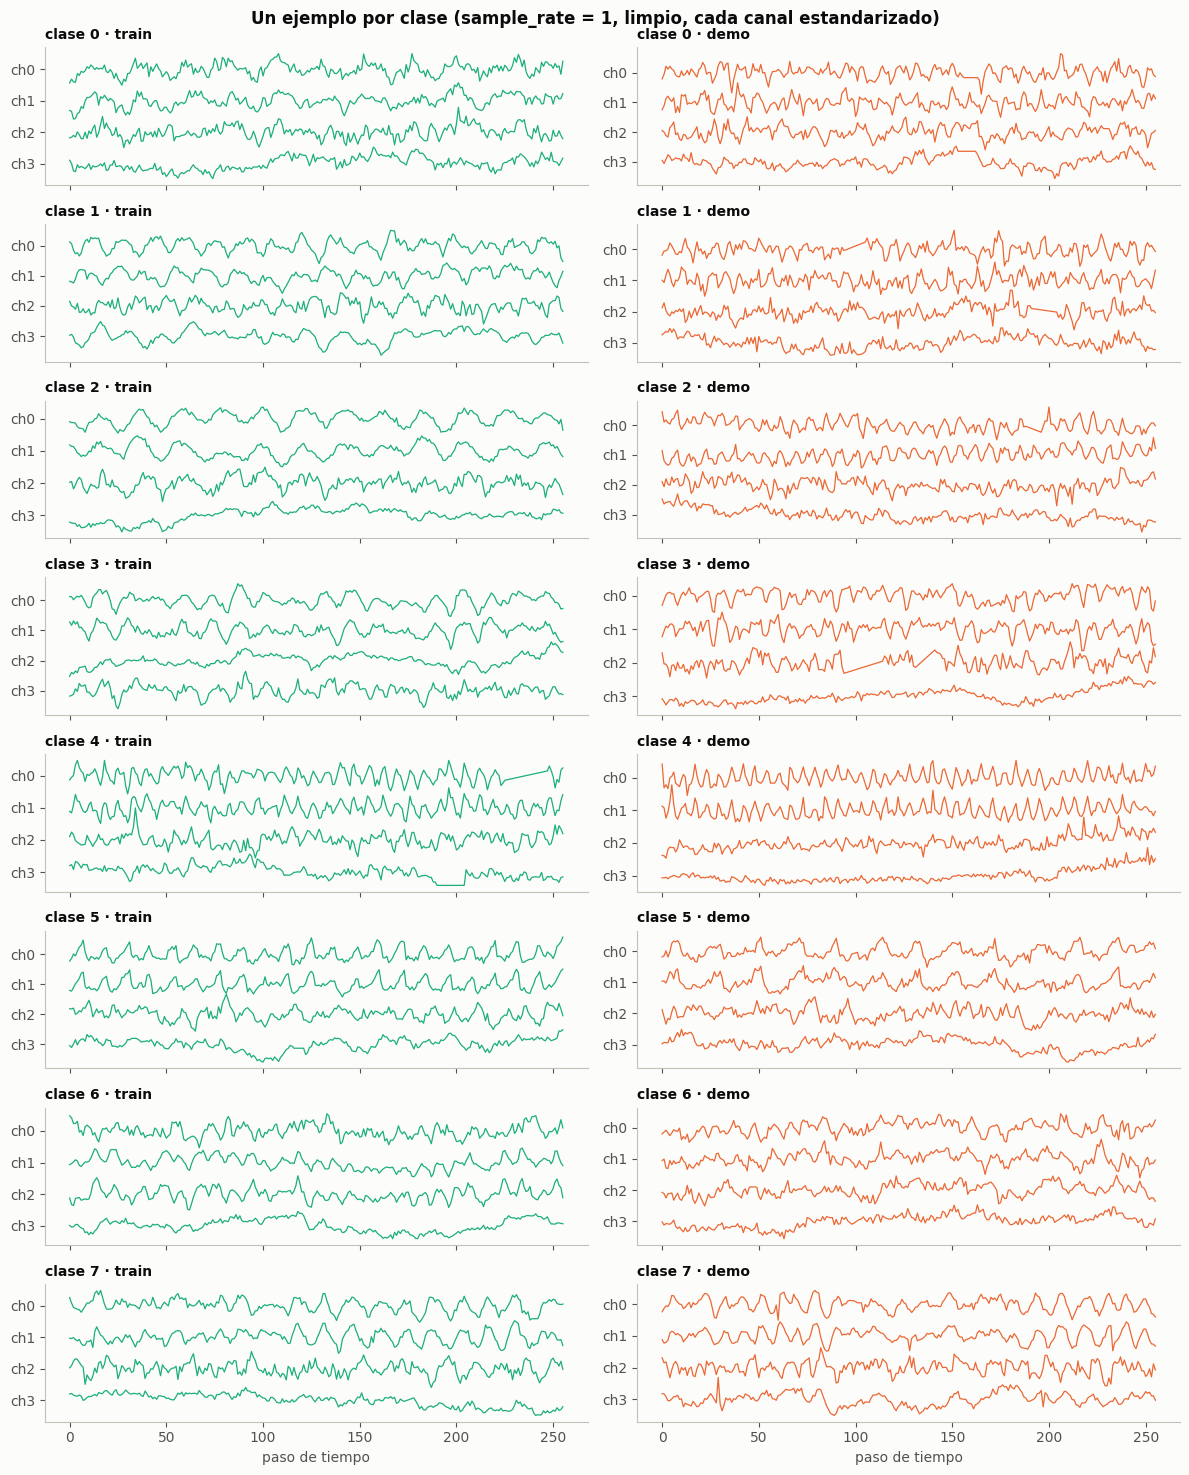

In [8]:
GANANCIA = {"A": 1.0, "B": 2.0, "C": 4.0}
yS, srS, gS = TR["y"][S], TR["sr"][S], TR["g"][S]
t0 = time.time()
XS = pp.limpiar_lotes(TR["X"][S]); XD = pp.limpiar(DE["X"])
print(f"limpieza de {len(XS) + len(XD)} muestras: {time.time() - t0:.1f} s")

fig, axes = plt.subplots(K, 2, figsize=(12, 15), sharex=True)
for k in CLASES:
    for j, (nom, X, y, sr, col) in enumerate((("train", XS, yS, srS, C_TRAIN), ("demo", XD, DE["y"], DE["sr"], C_DEMO))):
        i = np.flatnonzero((y == k) & (sr == 1.0))[0]
        Z = X[i] / (X[i].std(-1, keepdims=True) + 1e-9)
        ax = axes[k, j]
        for c in range(4):
            ax.plot(Z[c] - 5 * c, color=col, lw=0.9)
        ax.set_yticks([0, -5, -10, -15]); ax.set_yticklabels(["ch0", "ch1", "ch2", "ch3"]); ax.grid(False)
        ax.set_title(f"clase {k} · {nom}", loc="left", fontsize=10)
axes[-1, 0].set_xlabel("paso de tiempo"); axes[-1, 1].set_xlabel("paso de tiempo")
fig.suptitle("Un ejemplo por clase (sample_rate = 1, limpio, cada canal estandarizado)", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura.** A simple vista todas las clases son oscilaciones ruidosas: el ojo no basta. Los dos patrones que se intuyen (canales 0 y 1 que oscilan a la par y un canal 3 más lento) los medimos a continuación.

### Frecuencias: el espectro y el papel de `sample_rate`

**Ejemplo.** Un columpio que va y viene 17 veces en la ventana de 256 pasos tiene su energía en la "frecuencia 17". **Intuición:** el espectro reparte la varianza de la serie entre oscilaciones lentas (frecuencias bajas) y rápidas (altas); una oscilación periódica aparece como un pico. **Matemáticas:** la transformada de Fourier discreta $X_f=\sum_{t=0}^{255}x_t\,w_t\,e^{-2\pi i f t/256}$ y la potencia $|X_f|^2$ en cada *bin* $f=0..128$ ($f$ ciclos por ventana). Multiplicamos por una ventana de Hann $w_t$ para evitar la "fuga espectral" que crea el salto entre el final y el principio de la serie.

Si `sample_rate` = 2 significa "dos medidas por unidad de tiempo", la misma oscilación física ocupa el doble de pasos y su pico debe aparecer en la **mitad** del bin. Lo comprobamos.

sample_rate = 1: bin del pico de ch0, mediana train 19 | demo 20
sample_rate = 2: bin del pico de ch0, mediana train 9 | demo 9

frecuencia física del pico de ch0 (bin × sample_rate), percentiles 10/50/90 por clase:


,train p10,train p50,train p90,demo p10,demo p50,demo p90
clase,,,,,,
0,12.0,20.0,35.0,12.0,21.0,36.0
1,12.0,20.0,36.0,11.9,18.0,33.1
2,12.0,20.0,35.0,14.0,20.0,34.4
3,12.0,20.0,36.0,11.9,19.5,34.0
4,12.0,21.0,38.0,10.9,21.0,36.2
5,12.0,20.0,38.0,12.0,19.0,38.1
6,6.0,15.0,32.0,6.0,18.0,31.2
7,6.0,16.0,32.0,6.0,16.0,28.1


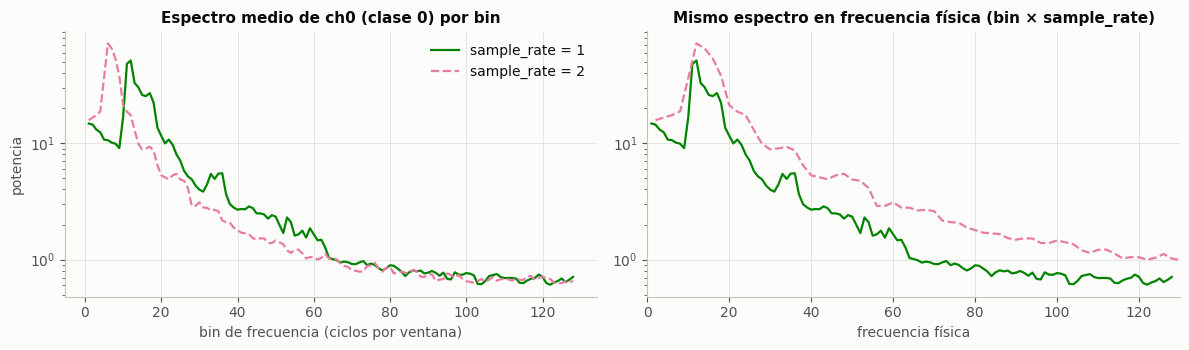

In [9]:
VENTANA = np.hanning(256).astype(np.float32)
def potencia(X):
    return np.abs(np.fft.rfft(X * VENTANA, axis=-1)) ** 2 / (VENTANA ** 2).sum()

PS, PD = potencia(XS), potencia(XD)
picoS = np.argmax(PS[..., 3:], axis=-1) + 3; picoD = np.argmax(PD[..., 3:], axis=-1) + 3   # pico de cada canal (sin tendencia)
for s in (1.0, 2.0):
    print(f"sample_rate = {s:.0f}: bin del pico de ch0, mediana train {np.median(picoS[srS == s, 0]):.0f} | demo {np.median(picoD[DE['sr'] == s, 0]):.0f}")

fis = pd.DataFrame({f"{nom} p{q}": [np.percentile((pk[:, 0] * sr)[y == k], q) for k in CLASES]
                    for nom, pk, sr, y in (("train", picoS, srS, yS), ("demo", picoD, DE["sr"], DE["y"])) for q in (10, 50, 90)},
                   index=pd.Index(CLASES, name="clase"))
print("\nfrecuencia física del pico de ch0 (bin × sample_rate), percentiles 10/50/90 por clase:")
display(fis)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
f = np.arange(129)
for s, col, ls in ((1.0, C_A, "-"), (2.0, C_B, "--")):
    m = (yS == 0) & (srS == s)
    ax[0].semilogy(f[1:], PS[m, 0, 1:].mean(0), color=col, ls=ls, label=f"sample_rate = {s:.0f}")
    ax[1].semilogy(f[1:] * s, PS[m, 0, 1:].mean(0), color=col, ls=ls, label=f"sample_rate = {s:.0f}")
ax[0].set(title="Espectro medio de ch0 (clase 0) por bin", xlabel="bin de frecuencia (ciclos por ventana)", ylabel="potencia")
ax[1].set(title="Mismo espectro en frecuencia física (bin × sample_rate)", xlabel="frecuencia física", xlim=(0, 130))
ax[0].legend(); plt.tight_layout(); plt.show()

**Lectura.**
* El pico de ch0 está en el bin **19** con `sample_rate` = 1 y en el **9** con `sample_rate` = 2: la misma oscilación ocupa el doble de pasos. `sample_rate` es la **frecuencia de muestreo**; expresando el eje en *frecuencia física* (bin × `sample_rate`) los dos espectros coinciden (gráfico de la derecha).
* La frecuencia física **se sortea en cada muestra** en un rango amplio (percentiles 10–90 ≈ 12–36), **igual en train y demo**; solo las clases 6 y 7 llegan más abajo (percentil 10 = 6). La frecuencia, por sí sola, **no identifica la clase**.

→ *Consecuencia:* los rasgos espectrales deben ir en frecuencia física (o ser invariantes a ella): un modelo que memorice bins concretos mezclaría `sample_rate` con la clase.

### Rasgos de "mecanismo": qué hace cada clase

Medimos, para cada muestra, rasgos interpretables que no dependen de la escala ni del nivel:

* **Correlación entre canales con retardo**. *Ejemplo:* dos relojes de péndulo; si van sincronizados, correlación +1; si uno va un cuarto de periodo por detrás, la correlación en el mismo instante es ≈ 0 pero, retrasando uno, vuelve a ser alta. *Matemáticas:* $\rho_{ab}(\tau)=\frac{1}{L}\sum_t z_a(t+\tau)\,z_b(t)$ con $z$ estandarizada.
* **Asimetría temporal** (`asimdif`): asimetría (sesgo) de las diferencias $x_{t+1}-x_t$. *Ejemplo:* un diente de sierra que sube despacio y cae de golpe tiene muchas diferencias pequeñas positivas y pocas negativas muy grandes → asimetría negativa; el que sube de golpe, positiva. Una sinusoide o un ruido gaussiano, ≈ 0.
* **Envolvente** (`envCV`): cuánto varía la amplitud de la oscilación a lo largo de la serie (coeficiente de variación de $|x + i\,\mathcal{H}x|$, la "señal analítica" de Hilbert). Una sinusoide pura, ≈ 0; una oscilación que se hincha y se deshincha, alta.
* **Memoria** (`acf1`, `acf4`: autocorrelación a 1 y 4 pasos), **cruces por cero**, **asimetría** y **curtosis** de los valores, **pendiente** y **amplitudes relativas** entre canales.

Para cada clase y rasgo calculamos el **AUC uno-contra-resto**: la probabilidad de que una muestra de esa clase tenga un valor mayor que una de otra clase (0.5 = no separa; 1 o 0 = separa perfectamente). Lo calculamos en train y en demo: un rasgo útil **separa en los dos**.

In [10]:
def rasgos_mecanismo(X, sr, g):
    Xg = X / np.array([GANANCIA[a] for a in g], dtype=np.float32)[:, None, None]
    Z = X / (X.std(-1, keepdims=True) + 1e-9)
    d = np.diff(X, axis=-1); dz = (d - d.mean(-1, keepdims=True)) / (d.std(-1, keepdims=True) + 1e-9)
    H = np.zeros(256); H[0] = 1; H[1:128] = 2; H[128] = 1
    env = np.abs(np.fft.ifft(np.fft.fft(X, axis=-1) * H, axis=-1))[..., 16:-16]
    pico = np.argmax(potencia(X)[..., 3:], axis=-1) + 3
    t = (np.arange(256) - 127.5) / 256
    F = {}
    for c in range(4):
        F[f"std_{c}"] = Xg[:, c].std(-1)
        F[f"acf1_{c}"] = (Z[:, c, 1:] * Z[:, c, :-1]).mean(-1)
        F[f"acf4_{c}"] = (Z[:, c, 4:] * Z[:, c, :-4]).mean(-1)
        F[f"cruces_{c}"] = (np.diff(np.sign(X[:, c]), axis=-1) != 0).mean(-1)
        F[f"asimdif_{c}"] = (dz[:, c] ** 3).mean(-1)
        F[f"asim_{c}"] = (Z[:, c] ** 3).mean(-1)
        F[f"curt_{c}"] = (Z[:, c] ** 4).mean(-1)
        F[f"envCV_{c}"] = env[:, c].std(-1) / (env[:, c].mean(-1) + 1e-9)
        F[f"fpico_{c}"] = pico[:, c] * sr
        F[f"pend_{c}"] = (Z[:, c] * t).sum(-1) / (t ** 2).sum()
    def xc(a, b, lag=0):   # correlación entre el canal a en t+lag y el canal b en t
        return (Z[:, a] * Z[:, b]).mean(-1) if lag == 0 else (Z[:, a, lag:] * Z[:, b, :-lag]).mean(-1)
    F.update({"corr01": xc(0, 1), "corr01_L4": xc(0, 1, 4), "corr10_L4": xc(1, 0, 4), "corr12": xc(1, 2), "corr02": xc(0, 2),
              "corr13": xc(1, 3), "corr23": xc(2, 3), "corr03_L4": xc(0, 3, 4), "corr02_L4": xc(0, 2, 4),
              "log_sd1/sd0": np.log(F["std_1"] / F["std_0"]), "log_sd2/sd0": np.log(F["std_2"] / F["std_0"]),
              "log_sd3/sd2": np.log(F["std_3"] / F["std_2"])})
    return pd.DataFrame(F)

FS, FD = rasgos_mecanismo(XS, srS, gS), rasgos_mecanismo(XD, DE["sr"], DE["g"])
yD = DE["y"]

def auc_ovr(F, y):
    return pd.DataFrame({k: [roc_auc_score(y == k, F[c]) for c in F.columns] for k in CLASES}, index=F.columns)

A_tr, A_de = auc_ovr(FS, yS), auc_ovr(FD, yD)
filas = []
for k in CLASES:
    dt, dd = A_tr[k] - 0.5, A_de[k] - 0.5
    robusto = (np.minimum(dt.abs(), dd.abs()) * (np.sign(dt) == np.sign(dd))).sort_values(ascending=False)
    trampa = (dt.abs() - dd.abs()).sort_values(ascending=False)
    for tipo, serie in (("robusto", robusto.index[:3]), ("trampa", trampa.index[:2])):
        for r in serie:
            filas.append({"clase": k, "tipo": tipo, "rasgo": r, "AUC train": A_tr.loc[r, k], "AUC demo": A_de.loc[r, k],
                          "mediana train (clase)": FS.loc[yS == k, r].median(), "mediana demo (clase)": FD.loc[yD == k, r].median()})
tabla_mec = pd.DataFrame(filas).set_index(["clase", "tipo", "rasgo"])
display(tabla_mec.round(3))

AUC train  AUC demo  mediana train (clase)  mediana demo (clase)
clase tipo    rasgo                                                                        
0     robusto std_1            0.343     0.376                  0.793                 0.815
              std_0            0.383     0.384                  0.792                 0.860
              corr03_L4        0.386     0.347                 -0.141                -0.182
      trampa  envCV_1          0.383     0.480                  0.477                 0.516
              curt_0           0.392     0.475                  2.670                 2.911
1     robusto corr01           0.025     0.009                  0.012                 0.004
              corr13           0.118     0.195                 -0.176                -0.118
              corr10_L4        0.201     0.208                 -0.301                -0.278
      trampa  corr13           0.118     0.195                 -0.176                -0.118
              acf4_2           0.428     0.493                  0.180                 0.172
2     robusto corr03_L4        0.857     0.891                  0.213                 0.182
              acf1_1           0.764     0.739                  0.859                 0.789
              cruces_1         0.288     0.268                  0.161                 0.180
      trampa  curt_0           0.290     0.416                  2.551                 2.710
              acf1_0           0.791     0.701                  0.859                 0.780
3     robusto envCV_1          0.700     0.723                  0.527                 0.550
              envCV_0          0.695     0.676                  0.527                 0.540
              curt_1           0.647     0.693                  2.970                 3.258
      trampa  acf4_3           0.226     0.507                  0.423                 0.640
              acf1_2           0.725     0.513                  0.804                 0.575
4     robusto asimdif_1        0.949     0.914                  0.746                 0.461
              asimdif_0        0.949     0.910                  0.752                 0.609
              asim_0           0.814     0.830                  0.483                 0.580
      trampa  acf4_2           0.402     0.509                  0.166                 0.184
              acf1_2           0.419     0.495                  0.621                 0.573
5     robusto asimdif_0        0.047     0.097                 -0.787                -0.442
              asimdif_1        0.043     0.106                 -0.782                -0.434
              asim_1           0.816     0.827                  0.481                 0.467
      trampa  curt_0           0.662     0.564                  3.076                 2.989
              corr01           0.701     0.614                  0.729                 0.654
6     robusto corr12           0.810     0.664                  0.512                 0.162
              acf1_1           0.647     0.648                  0.825                 0.778
              corr13           0.660     0.637                  0.180                 0.162
      trampa  corr02_L4        0.744     0.492                  0.234                -0.030
              log_sd1/sd0      0.743     0.519                  0.248                 0.027
7     robusto corr01           0.716     0.681                  0.729                 0.664
              corr10_L4        0.699     0.657                  0.265                 0.230
              corr13           0.668     0.646                  0.185                 0.182
      trampa  log_sd2/sd0      0.278     0.388                 -0.545                -0.493
              std_0            0.688     0.601                  1.050                 1.159

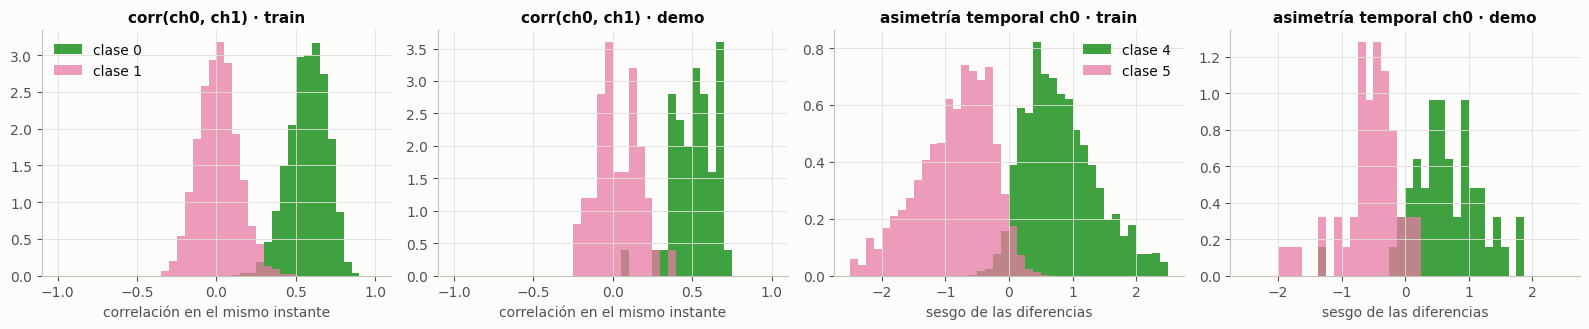

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
bins = np.linspace(-1, 1, 41)
for j, (nom, F, y) in enumerate((("train", FS, yS), ("demo", FD, yD))):
    for k, col in ((0, C_A), (1, C_B)):
        ax[j].hist(F.loc[y == k, "corr01"], bins=bins, density=True, color=col, alpha=0.75, label=f"clase {k}")
    ax[j].set(title=f"corr(ch0, ch1) · {nom}", xlabel="correlación en el mismo instante")
bins = np.linspace(-2.5, 2.5, 41)
for j, (nom, F, y) in enumerate((("train", FS, yS), ("demo", FD, yD))):
    for k, col in ((4, C_A), (5, C_B)):
        ax[2 + j].hist(F.loc[y == k, "asimdif_0"], bins=bins, density=True, color=col, alpha=0.75, label=f"clase {k}")
    ax[2 + j].set(title=f"asimetría temporal ch0 · {nom}", xlabel="sesgo de las diferencias")
ax[0].legend(); ax[2].legend(); plt.tight_layout(); plt.show()

**Lectura: el mecanismo de cada clase** (AUC uno-contra-resto en train / demo):
* **Clase 1**: ch0 y ch1 oscilan **desfasados un cuarto de periodo**, así que `corr01` ≈ 0 (AUC 0.025 / 0.009: separa al 97–99 %). La clase 0 los tiene en fase (gráfico, paneles 1–2).
* **Clases 4 y 5**: **diente de sierra** con la asimetría temporal invertida: `asimdif` positivo en la 4 (AUC 0.95 / 0.91) y negativo en la 5 (0.05 / 0.10). Es lo único que las separa entre sí (paneles 3–4).
* **Clase 2**: **ch3 adelanta a ch0** unos 4 pasos (`corr03_L4`, AUC 0.86 / 0.89) y ch1 es más suave.
* **Clase 3**: la amplitud de la oscilación **sube y baja** (envolvente variable, `envCV` AUC 0.70 / 0.72, más curtosis). Es el rasgo más débil: **clase en riesgo**.
* **Clase 6**: **ch1 y ch2 acoplados** (`corr12`: AUC 0.81 en train pero solo 0.66 en demo, ver 1.8) y ch1 más suave.
* **Clase 7**: ch0 y ch1 **muy correlados** (`corr01` AUC 0.72 / 0.68) y frecuencias más bajas.
* **Clase 0**: sin rasgo propio fuerte (algo menos de amplitud, AUC 0.34–0.38): es la oscilación "base" en fase y se reconocerá por exclusión.

Todos estos mecanismos **se mantienen en el demo** y serán la base de los rasgos y los modelos. Las filas *trampa* separan en train y mucho menos en demo; las más grandes son de las clases 3 y 6.

## 1.8 Trampas del train: canales intercambiados en las clases 3 y 6

La tabla anterior marca "trampas": rasgos que separan una clase en train pero no en demo. Casi todas son de las clases **3** (canales 2 y 3) y **6** (canales 0, 1 y 2). Hipótesis: en una parte del train esas clases tienen **dos canales intercambiados**. Si es así:

* en la clase 3, el canal 2 sería a veces "más suave" que el 3 (lo normal es al revés);
* en la clase 6, el canal 1 se parecería más al 2 que al 0;
* y los valores del canal "intercambiado" tendrían exactamente la distribución del canal original.

clase,0,1,2,3,4,5,6,7
train: acf4(ch2) > acf4(ch3),0.000,0.000,0.002,0.512,0.001,0.002,0.022,0.002
demo: acf4(ch2) > acf4(ch3),0.020,0.000,0.000,0.000,0.000,0.000,0.000,0.000
"train: corr(ch1,ch2) > corr(ch1,ch0)",0.002,0.246,0.004,0.002,0.000,0.000,0.505,0.000
"demo: corr(ch1,ch2) > corr(ch1,ch0)",0.000,0.240,0.000,0.000,0.000,0.000,0.000,0.000


,p10 rara,p50 rara,p90 rara,p10 referencia,p50 referencia,p90 referencia
comparación,,,,,,
clase 3 rara: acf1_2 vs otras clases: acf1_3,0.814,0.898,0.944,0.810,0.899,0.947
clase 3 rara: cruces_2 vs otras clases: cruces_3,0.078,0.133,0.196,0.082,0.133,0.196
clase 6 rara: std_2 vs clase 6 normal: std_0,0.724,1.049,1.445,0.735,1.068,1.518
clase 6 rara: acf4_2 vs clase 6 normal: acf4_0,-0.288,0.364,0.676,-0.284,0.317,0.659


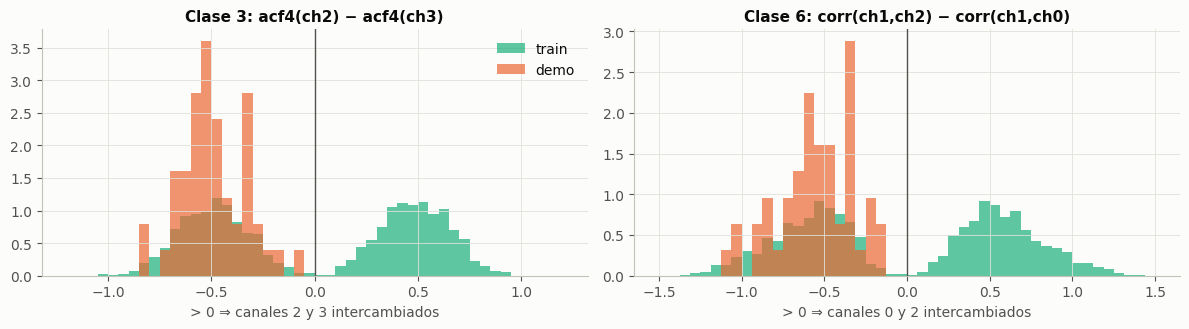

In [12]:
regla3 = (FS["acf4_2"] > FS["acf4_3"]).values; regla3D = (FD["acf4_2"] > FD["acf4_3"]).values
regla6 = (FS["corr12"] > FS["corr01"]).values; regla6D = (FD["corr12"] > FD["corr01"]).values
display(pd.DataFrame({"train: acf4(ch2) > acf4(ch3)": [regla3[yS == k].mean() for k in CLASES],
                      "demo: acf4(ch2) > acf4(ch3)": [regla3D[yD == k].mean() for k in CLASES],
                      "train: corr(ch1,ch2) > corr(ch1,ch0)": [regla6[yS == k].mean() for k in CLASES],
                      "demo: corr(ch1,ch2) > corr(ch1,ch0)": [regla6D[yD == k].mean() for k in CLASES]},
                     index=pd.Index(CLASES, name="clase")).T.round(3))

# ¿coinciden las distribuciones? clase 3 'rara' (ch2<->ch3) frente a las clases sin rol en ch2/ch3; clase 6 'rara' frente a la 6 normal
q = [10, 50, 90]
otras = np.isin(yS, [0, 1, 4, 5, 7])
r3, r6, n6 = (yS == 3) & regla3, (yS == 6) & regla6, (yS == 6) & ~regla6
comp = []
for a, b in (("acf1_2", "acf1_3"), ("cruces_2", "cruces_3")):
    comp.append({"comparación": f"clase 3 rara: {a}  vs  otras clases: {b}", **{f"p{x} rara": np.percentile(FS.loc[r3, a], x) for x in q},
                 **{f"p{x} referencia": np.percentile(FS.loc[otras, b], x) for x in q}})
for a, b in (("std_2", "std_0"), ("acf4_2", "acf4_0")):
    comp.append({"comparación": f"clase 6 rara: {a}  vs  clase 6 normal: {b}", **{f"p{x} rara": np.percentile(FS.loc[r6, a], x) for x in q},
                 **{f"p{x} referencia": np.percentile(FS.loc[n6, b], x) for x in q}})
display(pd.DataFrame(comp).set_index("comparación").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for nom, F, y, col in (("train", FS, yS, C_TRAIN), ("demo", FD, yD, C_DEMO)):
    ax[0].hist((F["acf4_2"] - F["acf4_3"])[y == 3], bins=np.linspace(-1.2, 1.2, 49), density=True, color=col, alpha=0.7, label=nom)
    ax[1].hist((F["corr12"] - F["corr01"])[y == 6], bins=np.linspace(-1.5, 1.5, 49), density=True, color=col, alpha=0.7, label=nom)
ax[0].axvline(0, color=TINTA2, lw=1); ax[1].axvline(0, color=TINTA2, lw=1)
ax[0].set(title="Clase 3: acf4(ch2) − acf4(ch3)", xlabel="> 0 ⇒ canales 2 y 3 intercambiados")
ax[1].set(title="Clase 6: corr(ch1,ch2) − corr(ch1,ch0)", xlabel="> 0 ⇒ canales 0 y 2 intercambiados")
ax[0].legend(); plt.tight_layout(); plt.show()

**Lectura.** La hipótesis se confirma con tres pruebas independientes:
1. En train, el **51.2 %** de la clase 3 tiene el canal 2 más suave que el 3 (resto de clases ≤ 2.2 %), y el **50.5 %** de la clase 6 tiene ch1 más parecido a ch2 que a ch0 (resto ≤ 0.4 %, salvo la clase 1, que lo cumple en el 25 % **igual en train que en demo** porque su ch0–ch1 está desfasado). **En el demo: 0 de 50** en las dos clases.
2. Los valores del canal "raro" tienen **la misma distribución** que el canal con el que se intercambió (p. ej., `acf1` del ch2 raro de la clase 3: mediana 0.898, frente a 0.899 del ch3 normal).
3. Los histogramas del train tienen **dos jorobas**, una a cada lado de 0; el demo, solo la de los canales en su sitio.

Es un **atajo plantado en el train**: la mitad de las clases 3 y 6 llevan canales permutados, y un modelo aprendería reglas como "ch2 suave ⇒ clase 3" o "ch2 grande y acoplado a ch1 ⇒ clase 6", que en el test no existen.

In [13]:
def desintercambiar(X, y, F):
    """Devuelve el train con los canales en su orden 'de test' (solo para entrenar: usa la etiqueta)."""
    X = X.copy()
    s3 = (y == 3) & (F["acf4_2"].values > F["acf4_3"].values)
    s6 = (y == 6) & (F["corr12"].values > F["corr01"].values)
    X[s3] = X[s3][:, [0, 1, 3, 2]]
    X[s6] = X[s6][:, [2, 1, 0, 3]]
    return X, s3, s6

XSu, s3, s6 = desintercambiar(XS, yS, FS)
FSu = rasgos_mecanismo(XSu, srS, gS)
A_tru = auc_ovr(FSu, yS)
print(f"intercambiadas: clase 3 → {s3.sum()} de {(yS == 3).sum()} ({s3.sum() / (yS == 3).sum():.1%}); "
      f"clase 6 → {s6.sum()} de {(yS == 6).sum()} ({s6.sum() / (yS == 6).sum():.1%})")
trampas = tabla_mec.xs("trampa", level="tipo").reset_index()
trampas["AUC train des-intercambiado"] = [A_tru.loc[r, k] for k, r in zip(trampas["clase"], trampas["rasgo"])]
display(trampas[["clase", "rasgo", "AUC train", "AUC train des-intercambiado", "AUC demo"]].round(3))

intercambiadas: clase 3 → 1025 de 2000 (51.2%); clase 6 → 1011 de 2000 (50.5%)


,clase,rasgo,AUC train,AUC train des-intercambiado,AUC demo
0,0,envCV_1,0.383,0.383,0.480
1,0,curt_0,0.392,0.403,0.475
2,1,corr13,0.118,0.108,0.195
3,1,acf4_2,0.428,0.468,0.493
4,2,curt_0,0.290,0.301,0.416
5,2,acf1_0,0.791,0.768,0.701
6,3,acf4_3,0.226,0.445,0.507
7,3,acf1_2,0.725,0.499,0.513
8,4,acf4_2,0.402,0.439,0.509
9,4,acf1_2,0.419,0.480,0.495


**Lectura.** Deshaciendo el intercambio (solo en el train, porque usa la etiqueta), los rasgos trampa de las clases 3 y 6 vuelven a su valor de test: `acf4_3` en la clase 3 pasa de AUC 0.226 a **0.445** (demo 0.507); `corr02_L4` en la 6, de 0.744 a **0.535** (demo 0.492); `log_sd1/sd0`, de 0.743 a **0.508** (demo 0.519). Las "trampas" de las demás clases son pequeñas (diferencias de AUC ≤ 0.14) y se parecen a lo que haría el ruido extra del test (1.9); lo comprobaremos en la Fase 2.
→ *Decisión:* **des-intercambiar el train** antes de entrenar. Es mejor que tirar esas muestras (perderíamos unas 6 000) o que permutar canales al azar (destruiría la identidad de cada canal, que es información: ch3 → ch0 en la clase 2).

## 1.9 Ruido: el test es más ruidoso

**Ejemplo.** La misma canción grabada con un micrófono peor: la melodía (frecuencias bajas) se oye igual, pero aparece un siseo constante en los agudos. **Intuición:** el ruido blanco reparte su potencia por igual en todas las frecuencias, así que se nota sobre todo donde la señal es débil: las frecuencias altas. **Matemáticas:** si $y=x+\varepsilon$ con $\varepsilon$ ruido blanco de varianza $\sigma^2$, la potencia esperada por bin es $P_y(f)=P_x(f)+\sigma^2$; la media de la potencia en los bins 100–128 (el "suelo") estima la varianza del ruido.

In [14]:
def suelo(P):   # varianza de ruido blanco equivalente por muestra y canal
    return P[..., 100:].mean(-1)
gananciaS = np.array([GANANCIA[a] for a in gS])[:, None]; gananciaD = np.array([GANANCIA[a] for a in DE["g"]])[:, None]
sueloS, sueloD = suelo(PS) / gananciaS ** 2, suelo(PD) / gananciaD ** 2
q = [5, 25, 50, 75, 95]
display(pd.DataFrame({**{f"train p{x}": np.percentile(np.log10(sueloS), x, axis=0) for x in q},
                      **{f"demo p{x}": np.percentile(np.log10(sueloD), x, axis=0) for x in q}},
                     index=pd.Index(range(4), name="canal")).round(2))
print("cociente demo/train de la mediana del suelo por canal:", (np.median(sueloD, 0) / np.median(sueloS, 0)).round(2))
amp = pd.DataFrame({f"{nom} std mediana": [np.median(X[gg == a].std(-1)) for a in "ABC"]
                    for nom, X, gg in (("train", XS, gS), ("demo", XD, DE["g"]))}, index=pd.Index(list("ABC"), name="group"))
amp["cociente demo/train"] = amp["demo std mediana"] / amp["train std mediana"]
display(amp.round(3))

,train p5,train p25,train p50,train p75,train p95,demo p5,demo p25,demo p50,demo p75,demo p95
canal,,,,,,,,,,
0,-1.74,-1.32,-1.06,-0.82,-0.53,-1.58,-1.12,-0.75,-0.49,-0.15
1,-1.75,-1.32,-1.06,-0.83,-0.52,-1.54,-1.11,-0.77,-0.48,-0.17
2,-1.66,-1.30,-1.07,-0.85,-0.57,-1.60,-1.18,-0.81,-0.56,-0.30
3,-2.11,-1.74,-1.47,-1.21,-0.86,-2.03,-1.48,-1.06,-0.80,-0.43


cociente demo/train de la mediana del suelo por canal: [2.04 1.98 1.8  2.58]


,train std mediana,demo std mediana,cociente demo/train
group,,,
A,0.760,0.774,1.019
B,1.518,1.807,1.190
C,3.045,3.297,1.083


**Lectura.** El suelo de ruido del demo es **2.0×** (ch0), **2.0×** (ch1), **1.8×** (ch2) y **2.6×** (ch3) el del train, y se desplaza toda la distribución (p95 de ch0: −0.53 → −0.15 en log10, ×2.4). En train el suelo ya varía mucho de una muestra a otra (p5–p95 ≈ ×16): el nivel de ruido se sortea por muestra, y en test se sortea más alto. La amplitud por grupo mantiene la proporción ×1 : ×2 : ×4, con un 2–19 % más en demo, compatible con el ruido añadido.
→ *Decisión:* **simular ruido** al entrenar (de entrada, ruido blanco que multiplica el suelo de cada muestra por un factor log-uniforme entre 1 y 4: ×2 en la mediana) y preferir rasgos que no dependan de las frecuencias altas. **No fiarse de la amplitud absoluta**: normalizar cada muestra.

## 1.10 Validación adversaria: ¿se distingue el train del test?

**Ejemplo.** Mezclamos fotos de dos cámaras y pedimos a alguien que adivine de qué cámara es cada una. Si acierta mucho, las cámaras dejan "huella". **Intuición:** entrenamos un clasificador para distinguir *train* de *demo*. Si no puede (AUC ≈ 0.5), los dos conjuntos se parecen; si puede, nos dice qué rasgos cambian. **Matemáticas:** AUC por validación cruzada (5 particiones estratificadas) de un `HistGradientBoostingClassifier` con clases equilibradas, sobre los rasgos de 1.7.

Lo repetimos cerrando, una a una, las diferencias encontradas: (a) tal cual tras limpiar; (b) añadiendo al train ruido blanco que multiplica su suelo por un factor log-uniforme entre 1 y 4; (c) además deshaciendo los intercambios de canales.

In [15]:
def anadir_ruido(X, rng, mult=(1.0, 4.0)):
    sue = suelo(potencia(X))
    m = np.exp(rng.uniform(np.log(mult[0]), np.log(mult[1]), size=(len(X), 1)))
    ruido = rng.standard_normal(X.shape).astype(np.float32) * np.sqrt(sue * (m - 1))[..., None].astype(np.float32)
    return pp.centrar(X + ruido)

def auc_adversaria(Fa, Fb):
    Xa = np.r_[Fa.values, Fb.values]; ya = np.r_[np.zeros(len(Fa)), np.ones(len(Fb))]
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, class_weight="balanced", random_state=SEMILLA)
    p = cross_val_predict(clf, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), method="predict_proba")[:, 1]
    return roc_auc_score(ya, p)

rng = np.random.default_rng(SEMILLA + 1)
FSr = rasgos_mecanismo(anadir_ruido(XS, rng), srS, gS)
FSru = rasgos_mecanismo(anadir_ruido(XSu, np.random.default_rng(SEMILLA + 1)), srS, gS)
adv = {"(a) limpio": auc_adversaria(FS, FD), "(b) + ruido simulado": auc_adversaria(FSr, FD),
       "(c) + ruido + des-intercambio": auc_adversaria(FSru, FD)}
for k, v in adv.items():
    print(f"AUC adversaria {k:32s}: {v:.3f}")
marg = pd.Series({c: roc_auc_score(np.r_[np.zeros(len(FSru)), np.ones(len(FD))], np.r_[FSru[c], FD[c]]) for c in FD.columns})
print("\nrasgos que más cambian aún (AUC univariante train simulado vs demo; 0.5 = igual):")
display(marg.sub(0.5).abs().sort_values(ascending=False).head(8).to_frame("|AUC − 0.5|").round(3))

AUC adversaria (a) limpio                      : 0.853
AUC adversaria (b) + ruido simulado            : 0.807
AUC adversaria (c) + ruido + des-intercambio   : 0.798



rasgos que más cambian aún (AUC univariante train simulado vs demo; 0.5 = igual):


,|AUC − 0.5|
cruces_2,0.122
acf1_2,0.113
log_sd3/sd2,0.095
curt_2,0.094
curt_1,0.082
curt_0,0.078
curt_3,0.070
log_sd2/sd0,0.066


**Lectura.** El clasificador distingue el train del demo con AUC **0.853**. Añadir el ruido la baja a **0.807** y deshacer los intercambios, a **0.798**. Sigue siendo alta: quedan diferencias en la **rugosidad del canal 2** (`cruces_2`, `acf1_2`), en la **curtosis** de todos los canales (colas más pesadas en el demo: picos moderados que el umbral 5× de Hampel deja pasar) y en la amplitud relativa ch3/ch2.
→ *Para la Fase 2:* calibrar el simulador (picos moderados, NaN y ruido por canal) hasta acercar esta AUC a 0.5, y comprobar qué rasgos resisten lo que quede.

## 1.11 Cierre de la Fase 1: train frente a test

| Propiedad | Train | Test (demo) | ¿Diferente? | Consecuencia para el modelo |
|---|---|---|---|---|
| Forma y tipo | 100 000 × 4 × 256, `float32` | 400 × 4 × 256, `float32` | No | — |
| Orden de las filas | ordenado por clase (7 cambios) | rachas de ~5 | Sí | validar con muestreo **aleatorio estratificado**, semilla fija |
| Balance de clases | 16.0 % … 9.9 % | 12.5 % exacto (el real puede cambiar) | Sí | **pesos equilibrados** (prior uniforme) |
| `group` | ⅓ A/B/C; ganancia ×1/×2/×4; independiente de la clase | igual; amplitud +2–19 % | Poco | **normalizar la amplitud** de cada muestra |
| `sample_rate` | ½ 1/2; escala el tiempo (pico en bin 19 → 9) | igual | No | rasgos en **frecuencia física** o invariantes |
| `level` (nivel) | clase 3 media +1.01, clase 5 −1.00; `level > 3` ⇒ clase 3 al 100 % | uniforme en [−4, 4]; `level > 3` ⇒ clase 3 el 13 % | **Sí: trampa** | **no usar `level`** |
| Media de ch3 − `level` | +0.99 en la clase 2, −1.00 en la 6 | ≈ 0 | **Sí: trampa** | **restar la media** de cada canal |
| Huecos (NaN) | 0.73 %; 83 % de un punto | 1.38 % (×1.9), misma forma | Sí | **interpolar**; simular hasta ×2 huecos; no usar % NaN |
| Picos (> 10× escala) | 0.02 % de las muestras | 14.5 % | **Sí** | **quitar picos** (Hampel); simular picos |
| Valores extremos | \|x\| ≤ 70.5 | \|x\| hasta 1678 | Sí | por los picos: robustez numérica |
| Ruido (suelo de alta frecuencia) | referencia | ×1.8–2.6 | **Sí** | **simular ruido**; rasgos de baja/media frecuencia |
| Canales intercambiados | clase 3: 51 % (ch2↔ch3); clase 6: 51 % (ch0↔ch2) | 0 % | **Sí: trampa** | **des-intercambiar el train** |
| Mecanismos de clase | fase ch0–ch1 (0/1), diente de sierra (4/5), ch3→ch0 (2), envolvente (3), ch1–ch2 (6), ch0–ch1 (7) | los mismos | No | base de rasgos y modelos |
| Frecuencia física | p10–p90 ≈ 12–36 (6–32 en las clases 6/7) | igual | No | la frecuencia sola no da la clase |
| Validación adversaria | — | AUC 0.853 → 0.798 tras ruido + des-intercambio | Sí | Fase 2: calibrar el simulador |

**Resumen de decisiones** (detalle y alternativas descartadas en `DECISIONES.md`, entradas D1–D9):

1. Validar con muestreo aleatorio estratificado, semilla fija.
2. No usar `level`; restar la media de cada canal.
3. Pesos de clase equilibrados.
4. Preprocesado: rellenar NaN → quitar picos → centrar (las variantes se comparan en la Fase 2).
5. Des-intercambiar los canales del train en las clases 3 y 6.
6. Entrenar con ruido, picos y huecos simulados.
7. Rasgos de mecanismo (fase y acoplamiento entre canales, asimetría temporal, envolvente, espectro en frecuencia física), invariantes a escala y nivel.

**Preguntas para la Fase 2:** ¿qué relleno de NaN y qué tratamiento de picos dejan los rasgos más parecidos entre train simulado y demo? ¿Qué simulador hace indistinguibles train y demo? ¿Cómo debe ser una validación que prediga la puntuación del test?

---
# Fase 2. Limpiar y preparar

La Fase 1 dejó una lista de problemas: **huecos** (×1.9 en test), **picos** (14.5 % de las muestras del demo), **ruido** (suelo ×2), dos **trampas** del train (nivel y canales intercambiados) y un **balance** distinto. En esta fase:

1. preparamos el train (deshacer intercambios, partición de validación);
2. para huecos y picos comparamos **al menos dos alternativas** con una métrica y elegimos;
3. construimos un **simulador** que lleva al train los problemas del test, calibrado contra el demo;
4. diseñamos una **validación que imite el test** y comprobamos que predice el demo;
5. escribimos el **estimador de la puntuación oficial** con el que se elegirá el modelo en la Fase 3.

Regla de oro: el preprocesado vive en `procesado.py` y es **el mismo** en el entrenamiento y en `predict`.

In [16]:
import inspect
from sklearn.model_selection import train_test_split

t_fase2 = time.time()
print(inspect.getsource(pp.limpiar))
print(inspect.getsource(pp.quitar_picos))

def limpiar(X: np.ndarray, picos: bool = True, umbral: float = 5.0) -> np.ndarray:
    """Cadena completa: rellenar NaN -> (quitar picos) -> centrar."""
    X = rellenar_nan(X)
    if picos:
        X = quitar_picos(X, umbral)
    return centrar(X).astype(np.float32, copy=False)

def quitar_picos(X: np.ndarray, umbral: float = 5.0) -> np.ndarray:
    """Filtro de Hampel: sustituye por la mediana móvil de 5 puntos los valores que se alejan de
    ella más de ``umbral`` veces la escala robusta DEL CANAL.

    La escala es la del canal entero, no la de la ventana: con 5 puntos la MAD local casi vale 0 y
    todo parecería un pico (probado en la Fase 1: marcaba el 4 % de los puntos del train).
    """
    X = np.asarray(X, dtype=np.float32)
    m5 = mediana_movil5(X)
    return np.where(np.abs(X - m5) > umbral * escala_robusta(X), m5, X)



## 2.1 Preparar el train: deshacer intercambios y partir para validar

* **Des-intercambio (D6).** Se limpia el train completo (rellenar → quitar picos → centrar) y se aplican las reglas de §1.8: en la clase 3, si `acf4(ch2) > acf4(ch3)` se devuelven ch2 y ch3 a su sitio; en la 6, si `corr(ch1,ch2) > corr(ch1,ch0)`, ch0 y ch2. Se corrige también la serie **cruda** (con sus NaN), porque el simulador trabaja sobre ella.
* **Partición (D1).** 80 % entrenamiento / 20 % validación, **estratificada por clase × `group` × `sample_rate`** y con semilla fija: las dos partes tienen las mismas proporciones de todo lo que sabemos que varía.

In [17]:
def desintercambiar_train(Xlimpio, Xcrudo, y):
    Z = Xlimpio / (Xlimpio.std(-1, keepdims=True) + 1e-9)
    acf4 = (Z[..., 4:] * Z[..., :-4]).mean(-1)
    s3 = (y == 3) & (acf4[:, 2] > acf4[:, 3])
    s6 = (y == 6) & ((Z[:, 1] * Z[:, 2]).mean(-1) > (Z[:, 0] * Z[:, 1]).mean(-1))
    sal = []
    for X in (Xlimpio, Xcrudo):
        X = X.copy(); X[s3] = X[s3][:, [0, 1, 3, 2]]; X[s6] = X[s6][:, [2, 1, 0, 3]]; sal.append(X)
    return sal[0], sal[1], s3, s6

Xc_tr = pp.limpiar_lotes(TR["X"])
Xc_tr, Xu_tr, s3, s6 = desintercambiar_train(Xc_tr, TR["X"], TR["y"])
print(f"des-intercambiadas: clase 3 → {s3.sum()} de {(TR['y'] == 3).sum()} ({100 * s3.mean() / (TR['y'] == 3).mean():.1f} %), "
      f"clase 6 → {s6.sum()} de {(TR['y'] == 6).sum()} ({100 * s6.mean() / (TR['y'] == 6).mean():.1f} %)")

estrato = TR["y"] * 100 + np.searchsorted(["A", "B", "C"], TR["g"]) * 10 + TR["sr"].astype(int)
i_tr, i_va = train_test_split(np.arange(len(TR["y"])), test_size=0.2, stratify=estrato, random_state=SEMILLA)
i_tr, i_va = np.sort(i_tr), np.sort(i_va)
y_tr, y_va = TR["y"][i_tr], TR["y"][i_va]
print(f"entrenamiento {len(i_tr)} | validación {len(i_va)} | clases en validación: {np.bincount(y_va)}")
esc_tr = pp.escala_robusta(Xc_tr)[..., 0]            # escala robusta de cada canal de la serie limpia
suelo_tr = (np.abs(np.fft.rfft(Xc_tr * VENTANA, axis=-1)) ** 2 / (VENTANA ** 2).sum())[..., 100:].mean(-1)

des-intercambiadas: clase 3 → 5969 de 11915 (50.1 %), clase 6 → 4999 de 10123 (49.4 %)
entrenamiento 80000 | validación 20000 | clases en validación: [3198 2806 2786 2384 2397 2432 2024 1973]


**Lectura.** Se des-intercambia aproximadamente la mitad de las clases 3 y 6, como en la Fase 1 (allí, con una submuestra). La validación tiene unas 20 000 muestras con el mismo desbalance que el train. Ese desbalance no importa: la métrica mide el acierto **por clase**.

## 2.2 Huecos (NaN): tres alternativas

**Ejemplo.** Un canal vale `…, 1.0, NaN, NaN, 4.0, …`. ¿Qué ponemos en los huecos?

* **Interpolación lineal**: una recta entre los vecinos válidos → `2.0, 3.0`.
* **Mediana del canal**: un valor constante (≈ 0 en una oscilación centrada).
* **Valor anterior** (*forward fill*): repetir el último válido → `1.0, 1.0`.

**Intuición.** La señal es una oscilación suave más ruido: entre dos puntos cercanos, lo más probable es algo intermedio. Una constante crea escalones, y la mediana mete un "cero" en mitad de una cresta.

**Matemáticas.** Si el hueco va de `a+1` a `b−1` (con `a` y `b` válidos):

$$\hat x(t) = x(a) + \frac{t-a}{b-a}\,\big(x(b)-x(a)\big), \qquad a < t < b.$$

En los bordes se copia el valor válido más cercano, y un canal sin ningún valor válido pasa a 0.

**Métrica 1 (reconstrucción).** Tomamos series **limpias** de validación, les quitamos puntos con la **forma real** de los huecos (máscaras de NaN de otras muestras del train) y medimos el error al rellenarlos, en unidades de la escala del canal. Así sabemos el valor verdadero de cada punto borrado.

In [18]:
def nan_mediana(X):
    A = np.array(X, dtype=np.float32); m = np.nanmedian(A, axis=-1, keepdims=True)
    return np.where(np.isnan(A), np.where(np.isnan(m), 0, m), A).astype(np.float32)

def nan_anterior(X):
    A = np.array(X, dtype=np.float32); ok = ~np.isnan(A); t = np.arange(A.shape[-1])
    prev = np.maximum.accumulate(np.where(ok, t, -1), axis=-1)
    nxt = np.minimum.accumulate(np.where(ok, t, A.shape[-1])[..., ::-1], axis=-1)[..., ::-1]
    out = np.take_along_axis(A, np.where(prev >= 0, prev, np.minimum(nxt, A.shape[-1] - 1)), -1)
    return np.where(np.isnan(out), 0, out).astype(np.float32)

ALT_NAN = {"interpolación lineal": pp.rellenar_nan, "mediana del canal": nan_mediana, "valor anterior": nan_anterior}

rng = np.random.default_rng(SEMILLA + 5)
B = np.sort(rng.choice(i_va, 4000, replace=False))
mascaras = np.isnan(TR["X"][np.sort(rng.choice(i_tr, 20000, replace=False))])     # huecos reales del train
verdad = Xc_tr[B]; escB = esc_tr[B][..., None]
con_huecos = verdad.copy(); con_huecos[mascaras[rng.integers(0, len(mascaras), len(B))]] = np.nan
hueco = np.isnan(con_huecos)
tabla_nan = pd.DataFrame({"RMSE en los huecos (escalas del canal)": [np.sqrt(((((f(con_huecos) - verdad) / escB)[hueco]) ** 2).mean()) for f in ALT_NAN.values()]},
                         index=pd.Index(list(ALT_NAN), name="alternativa"))
display(tabla_nan.round(3))

,RMSE en los huecos (escalas del canal)
alternativa,
interpolación lineal,0.912
mediana del canal,1.013
valor anterior,1.122


**Lectura.** La interpolación lineal es la que menos se equivoca (0.91 escalas frente a 1.01 de la mediana y 1.12 del valor anterior). El error no baja de ahí porque el 14 % de los huecos son rachas de 6 a 30 puntos: ahí cabe medio periodo de la oscilación y ningún relleno simple lo recupera. Lo comprobaremos también aguas abajo, en el acierto (§2.5).
→ *Decisión (D4, confirmada):* **interpolación lineal**.

## 2.3 Picos: cinco alternativas

**Ejemplo.** Un canal oscila entre −1 y 1 y, de golpe, un punto vale 40. Si lo dejamos, la desviación típica de ese canal se multiplica por 2.5, la correlación con los otros canales se desploma y el espectro se llena de una línea plana (un impulso tiene todas las frecuencias).

**Alternativas.**
* **Nada**: dejar el pico.
* **Recorte 5×**: limitar cada valor a mediana ± 5 escalas (*winsorizar*). El pico se queda en 5.
* **Filtro de Hampel** con umbral 3×, 5× u 8×: si un punto se aleja de la **mediana de su ventana de 5** más de *umbral* × escala del canal, se sustituye por esa mediana.

**Intuición.** La mediana de 5 puntos ignora un valor raro: si la ventana es `0.2, 0.5, 40, 0.7, 0.4`, la mediana es 0.5. Un pico aislado no la mueve; la oscilación, que es suave, sí. Por eso "lejos de la mediana local" equivale a "pico".

**Matemáticas.** Con $m_t = \mathrm{mediana}(x_{t-2},\dots,x_{t+2})$ y la escala robusta del canal $s = \mathrm{IQR}/1.349$ (igual a la desviación típica si los datos son gaussianos, e insensible a unos pocos valores extremos):

$$x_t \leftarrow \begin{cases} m_t & \text{si } |x_t - m_t| > u \cdot s \\ x_t & \text{si no} \end{cases}$$

La escala es la del **canal entero**. La de la ventana no sirve: con 5 puntos la dispersión local casi vale 0 y todo parecería un pico (en la Fase 1 marcaba el 4 % de los puntos). La mediana de 5 se calcula con una red de 10 comparaciones `min`/`max`, unas 4 veces más rápida que `np.median`, porque esto también corre dentro de `predict`.

**Métricas.** Inyectamos picos con la distribución medida en el demo (§2.4) en series limpias y medimos el error total frente a la serie limpia, el % de picos grandes (> 5×) corregidos y el % de puntos **sanos** que el método altera (falsos positivos).

## 2.4 El simulador del test

Para que el modelo aprenda con datos como los del test, y para validar como si fuera el test, llevamos al train sus tres problemas. Cada parámetro sale de una medida del demo, que se usa **sin etiquetas** (D9).

1. **Ruido blanco.** El suelo de ruido de cada canal se multiplica por $m_c = M_c^{\,u}$, con $u \sim U(0,1)$ **común a los 4 canales** de la muestra: en el demo, el suelo de los cuatro canales está muy correlacionado (0.86–0.91), así que el nivel de ruido se sortea por muestra. $M_c$ se elige por canal minimizando la distancia KS entre la distribución del log-suelo simulado y la del demo.
2. **Picos de un punto.** Con probabilidad $p$, la muestra recibe $1 + \text{Poisson}(\lambda)$ picos en canal y posición al azar, con signo ±. La amplitud, en escalas del canal, sigue el **exceso del demo sobre el train** por tramos (3–4×, 4–6×, … hasta 1000×).
3. **Huecos.** Se **trasplanta la máscara de NaN de otra muestra del train**: los huecos se duplican (0.73 % → ~1.4 %) conservando exactamente su forma (rachas de 1, de 6–30…).

In [19]:
BORDES = np.array([3, 4, 6, 10, 16, 32, 100, 316, 1000], dtype=np.float64)

def simular(X, esc, suelo, mascaras, rng, M=(4, 4, 4, 4), p_pico=0.25, lam=2.5, pesos=None, ruido=True, picos=True, nan=True):
    """Lleva series crudas del train (n,4,256) a las condiciones del test. esc, suelo: (n,4) de la serie limpia."""
    n = len(X)
    Y = np.array(X, dtype=np.float32, copy=True)
    if ruido:
        u = rng.uniform(size=(n, 1))
        m = np.exp(u * np.log(np.asarray(M, dtype=np.float64))[None, :])
        Y += rng.standard_normal(Y.shape, dtype=np.float32) * np.sqrt(suelo * (m - 1)).astype(np.float32)[..., None]
    if picos:
        k = np.where(rng.uniform(size=n) < p_pico, 1 + rng.poisson(lam, size=n), 0)
        i = np.repeat(np.arange(n), k); tot = len(i)
        c, t = rng.integers(0, 4, tot), rng.integers(0, X.shape[-1], tot)
        w = np.ones(len(BORDES) - 1) if pesos is None else np.asarray(pesos, dtype=np.float64)
        b = rng.choice(len(w), size=tot, p=w / w.sum())
        r = np.exp(rng.uniform(np.log(BORDES[b]), np.log(BORDES[b + 1])))
        Y[i, c, t] += (rng.choice(np.array([-1.0, 1.0]), size=tot) * r * esc[i, c]).astype(np.float32)
    if nan:
        Y[mascaras[rng.integers(0, len(mascaras), n)]] = np.nan
    return Y

def residuo_picos(Xf):     # |x − mediana móvil| en escalas del canal, sobre series sin NaN
    return np.abs(Xf - pp.mediana_movil5(Xf)) / pp.escala_robusta(Xf)

def suelo_de(X):
    return (np.abs(np.fft.rfft(X * VENTANA, axis=-1)) ** 2 / (VENTANA ** 2).sum())[..., 100:].mean(-1)

def ks(a, b):
    a, b = np.sort(a), np.sort(b); x = np.r_[a, b]
    return np.max(np.abs(np.searchsorted(a, x, side="right") / len(a) - np.searchsorted(b, x, side="right") / len(b)))

S2 = np.sort(np.random.default_rng(SEMILLA + 1).choice(i_tr, 16000, replace=False))     # submuestra para calibrar
log_suelo_demo = np.log(suelo_de(pp.limpiar_lotes(DE["X"])))
filas = []
for M in (1.5, 2, 3, 4, 5, 6, 8):
    Xs = pp.limpiar_lotes(simular(Xu_tr[S2], esc_tr[S2], suelo_tr[S2], mascaras, np.random.default_rng(2), M=(M,) * 4, picos=False))
    ls = np.log(suelo_de(Xs))
    filas.append({"M": M, **{f"KS canal {c}": ks(ls[:, c], log_suelo_demo[:, c]) for c in range(4)}})
tabla_M = pd.DataFrame(filas).set_index("M")
M_CAL = tuple(float(tabla_M[f"KS canal {c}"].idxmin()) for c in range(4))
display(tabla_M.round(3))
print("M elegido por canal:", M_CAL, "| % NaN tras simular:", round(100 * np.isnan(simular(Xu_tr[S2[:2000]], esc_tr[S2[:2000]], suelo_tr[S2[:2000]], mascaras, np.random.default_rng(2), picos=False, ruido=False)).mean(), 2),
      "(demo:", round(100 * np.isnan(DE["X"]).mean(), 2), ")")

,KS canal 0,KS canal 1,KS canal 2,KS canal 3
M,,,,
1.5,0.140,0.152,0.085,0.193
2.0,0.107,0.117,0.051,0.160
3.0,0.062,0.069,0.058,0.111
4.0,0.035,0.036,0.076,0.078
5.0,0.046,0.045,0.093,0.052
6.0,0.061,0.066,0.113,0.039
8.0,0.092,0.099,0.148,0.047


M elegido por canal: (4.0, 4.0, 2.0, 6.0) | % NaN tras simular: 1.44 (demo: 1.38 )


**Lectura.** El ruido que falta no es igual en todos los canales: el mejor $M$ es **4** en ch0 y ch1, **2** en ch2 y **6** en ch3, coherente con los cocientes de suelo de la Fase 1 (×2.0, ×2.0, ×1.8 y ×2.6). Con esos valores la distancia KS baja a 0.035–0.051; con un solo $M$ para todos (el de la Fase 1, $M = 4$) quedaba en 0.08 en ch2 y ch3. El trasplante de máscaras deja un 1.44 % de NaN, frente al 1.38 % del demo.

In [20]:
UMBRALES = [3, 4, 5, 8, 10, 20, 50, 100]
def tabla_picos(X):
    r = residuo_picos(pp.rellenar_nan(X))
    return [1000 * (r > u).sum() / (len(X) * 4) for u in UMBRALES]

Xn = simular(Xu_tr[S2], esc_tr[S2], suelo_tr[S2], mascaras, np.random.default_rng(2), M=M_CAL, picos=False)
r_s, r_d = residuo_picos(pp.rellenar_nan(Xn)), residuo_picos(pp.rellenar_nan(DE["X"]))
exceso = np.maximum(np.histogram(r_d[r_d > 3], BORDES)[0] / (len(DE["X"]) * 4) - np.histogram(r_s[r_s > 3], BORDES)[0] / (len(S2) * 4), 0)
PESOS = exceso / exceso.sum()
P_PICO, LAM = 0.25, 2.5    # p (1 + λ) ≈ 0.86 picos por muestra y P(≥1 pico > 5×) ≈ 0.21, como en el demo
Xsim = simular(Xu_tr[S2], esc_tr[S2], suelo_tr[S2], mascaras, np.random.default_rng(3), M=M_CAL, p_pico=P_PICO, lam=LAM, pesos=PESOS)
tabla_tasa_picos = pd.DataFrame({"train original": tabla_picos(TR["X"][S2]), "train simulado": tabla_picos(Xsim), "demo": tabla_picos(DE["X"])},
                                index=pd.Index([f"> {u}×" for u in UMBRALES], name="picos por 1000 (muestra, canal)"))
display(tabla_tasa_picos.round(1))

,train original,train simulado,demo
"picos por 1000 (muestra, canal)",,,
> 3×,38.5,220.0,248.1
> 4×,4.3,132.1,133.1
> 5×,0.9,101.0,100.0
> 8×,0.1,62.2,63.8
> 10×,0.1,48.7,49.4
> 20×,0.0,25.3,24.4
> 50×,0.0,10.2,8.8
> 100×,0.0,5.1,5.6


**Lectura.** El train original casi no tiene picos (1 por cada 1000 canales por encima de 5×). El simulado reproduce la tabla del demo en todos los umbrales: unos 100 por encima de 5×, 50 por encima de 10× y 5–6 por encima de 100×. Los parámetros salen de dos condiciones medidas en el demo. Hay unos 0.86 picos grandes por muestra, y el 21 % de las muestras tiene al menos uno por encima de 5×. Con $p = 0.25$ y $\lambda = 2.5$ se cumplen las dos: los picos van **agrupados** (algunas muestras tienen varios y la mayoría ninguno), como en el demo, donde una muestra con picos tiene ~1.9 de media.

In [21]:
PIC = {"nada": lambda X: X,
       "recorte 5×": lambda X: np.clip(X, pp._mediana(X) - 5 * pp.escala_robusta(X), pp._mediana(X) + 5 * pp.escala_robusta(X)),
       "Hampel 3×": lambda X: pp.quitar_picos(X, 3.0), "Hampel 5×": lambda X: pp.quitar_picos(X, 5.0), "Hampel 8×": lambda X: pp.quitar_picos(X, 8.0)}
con_picos = simular(verdad, esc_tr[B], suelo_tr[B], mascaras, np.random.default_rng(7), ruido=False, nan=False, p_pico=P_PICO, lam=LAM, pesos=PESOS)
inyectado, grande = np.abs(con_picos - verdad) > 1e-6, np.abs(con_picos - verdad) / escB > 5
filas = []
for nom, f in PIC.items():
    Z = f(con_picos); dif = np.abs(Z - verdad) / escB
    filas.append({"alternativa": nom, "RMSE total (escalas)": np.sqrt((dif ** 2).mean()), "% picos > 5× corregidos": 100 * (dif[grande] < 1).mean(),
                  "% puntos sanos alterados": 100 * (np.abs(Z - con_picos) > 1e-6)[~inyectado].mean()})
tabla_pic = pd.DataFrame(filas).set_index("alternativa")
display(tabla_pic.round(3))

,RMSE total (escalas),% picos > 5× corregidos,% puntos sanos alterados
alternativa,,,
nada,1.511,0.000,0.000
recorte 5×,0.131,0.000,0.009
Hampel 3×,0.092,86.190,0.014
Hampel 5×,0.110,80.441,0.000
Hampel 8×,0.136,51.746,0.000


**Lectura.**
* **No hacer nada** deja un error 14 veces mayor (1.51 escalas de RMSE).
* **Recortar** no corrige ningún pico: lo deja en 5 escalas, que sigue siendo un pico.
* **Hampel** corrige el 52 % (8×), el 80 % (5×) o el 86 % (3×) de los picos grandes. A 5× no toca **ningún** punto sano; a 3× ya altera algunos (0.014 %: uno de cada ~7 000).

Los picos que se escapan a 5× son los pequeños (5–6×), que el modelo verá igualmente al entrenar con el simulador.
→ *Decisión (D5, confirmada):* **Hampel 5×**. Es la opción más segura: cero falsos positivos con el 80 % de corrección. 3× arregla algo más, pero empieza a tocar la señal (crestas, flancos del diente de sierra), y en §2.5 no mejora el acierto de forma clara.

### ¿Se parecen ya train y test? Validación adversaria

Repetimos la prueba de §1.10 con los rasgos definitivos (`procesado.rasgos`, 109 rasgos de mecanismo que se definen en la Fase 3): un clasificador intenta distinguir 8 000 muestras del train de las 400 del demo. AUC 0.5 = indistinguibles.

In [22]:
def auc_adv(F, FD):
    Xa, ya = np.r_[F, FD], np.r_[np.zeros(len(F)), np.ones(len(FD))]
    clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, class_weight="balanced", random_state=SEMILLA)
    p = cross_val_predict(clf, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), method="predict_proba")[:, 1]
    return roc_auc_score(ya, p)

S3 = S2[::2]
F_demo = pp.rasgos(pp.limpiar_lotes(DE["X"]), DE["sr"])
sim3 = lambda **kw: pp.limpiar_lotes(simular(Xu_tr[S3], esc_tr[S3], suelo_tr[S3], mascaras, np.random.default_rng(4), **kw))
casos = {"(a) train original (con intercambios)": pp.limpiar_lotes(TR["X"][S3]),
         "(b) des-intercambiado": Xc_tr[S3],
         "(c) + ruido M=4 igual en todos (Fase 1)": sim3(M=(4,) * 4, picos=False, nan=False),
         "(d) + ruido calibrado por canal + NaN": sim3(M=M_CAL, picos=False),
         "(e) + picos: simulador completo": sim3(M=M_CAL, p_pico=P_PICO, lam=LAM, pesos=PESOS)}
nombres_r = pp.nombres_rasgos()
filas = []
for nom, Xc_ in casos.items():
    F = pp.rasgos(Xc_, TR["sr"][S3])
    marg = np.array([roc_auc_score(np.r_[np.zeros(len(F)), np.ones(len(F_demo))], np.r_[F[:, j], F_demo[:, j]]) for j in range(F.shape[1])])
    top = np.argsort(-np.abs(marg - 0.5))[:3]
    filas.append({"train": nom, "AUC adversaria": auc_adv(F, F_demo), "rasgos más distintos (AUC univariante)": ", ".join(f"{nombres_r[j]} {marg[j]:.2f}" for j in top)})
tabla_adv = pd.DataFrame(filas).set_index("train")
display(tabla_adv.round(3))

,AUC adversaria,rasgos más distintos (AUC univariante)
train,,
(a) train original (con intercambios),0.816,"rugosidad_3 0.73, acf1_3 0.27, acf2_3 0.33"
(b) des-intercambiado,0.794,"rugosidad_3 0.78, acf1_3 0.22, acf2_3 0.29"
(c) + ruido M=4 igual en todos (Fase 1),0.720,"rugosidad_2 0.39, acf1_2 0.61, lsd_rel_2 0.40"
(d) + ruido calibrado por canal + NaN,0.666,"curt_2 0.59, curt_1 0.59, curt_0 0.58"
(e) + picos: simulador completo,0.621,"curt_2 0.56, curt_1 0.55, curt_0 0.55"


**Lectura.** Cada paso acerca el train al test:

| Paso | AUC adversaria |
|---|---|
| Train original (con intercambios) | 0.816 |
| des-intercambiado | 0.794 |
| + ruido de la Fase 1 | 0.720 |
| + ruido calibrado y NaN | 0.666 |
| + picos (simulador completo) | 0.621 |

Lo que queda es poco: ningún rasgo por separado pasa de AUC ≈ 0.56. El mayor es la curtosis (colas algo más pesadas en el demo, quizá picos de menos de 3× que no simulamos).

El simulador no es perfecto, pero ya no hay una diferencia grande y sistemática que el modelo pueda tomar por señal. El des-intercambio apenas mueve la AUC global porque solo afecta a 2 de las 8 clases. Su efecto se ve en el acierto de esas clases (Fase 3).

## 2.5 ¿Cómo validar? Una validación que imite el test

**Propuesta.** El 20 % de validación, **pasado por el simulador con una semilla fija** ("val-sim"), y el demo como comprobación final (no se elige nada con él).

**¿Funciona?** Entrenamos el mismo modelo sencillo (HGB sobre los rasgos de mecanismo, 16 000 muestras) y comparamos lo que predice cada validación con lo que pasa en el demo. Medimos además las alternativas de NaN y de picos **aguas abajo**: el acierto final.

In [23]:
rng = np.random.default_rng(SEMILLA + 5)
A16 = np.sort(rng.choice(i_tr, 16000, replace=False))
simA = simular(Xu_tr[A16], esc_tr[A16], suelo_tr[A16], mascaras, np.random.default_rng(10), M=M_CAL, p_pico=P_PICO, lam=LAM, pesos=PESOS)
simB = simular(Xu_tr[B], esc_tr[B], suelo_tr[B], mascaras, np.random.default_rng(11), M=M_CAL, p_pico=P_PICO, lam=LAM, pesos=PESOS)

def hgb_rapido():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31, class_weight="balanced", random_state=SEMILLA)

def acierto_por_clase(y, p):
    return np.array([(p[y == k] == k).mean() for k in CLASES])

def preparar(X, f_nan, f_pic, sr):
    return pp.rasgos(pp.centrar(f_pic(f_nan(X))).astype(np.float32), sr)

filas = []
for nn, pn in [("interpolación lineal", "nada"), ("interpolación lineal", "recorte 5×"), ("interpolación lineal", "Hampel 3×"),
               ("interpolación lineal", "Hampel 5×"), ("interpolación lineal", "Hampel 8×"),
               ("mediana del canal", "Hampel 5×"), ("valor anterior", "Hampel 5×")]:
    fn, fp = ALT_NAN[nn], PIC[pn]
    m = hgb_rapido().fit(preparar(simA, fn, fp, TR["sr"][A16]), TR["y"][A16])
    pv, pdm = m.predict(preparar(simB, fn, fp, TR["sr"][B])), m.predict(preparar(DE["X"], fn, fp, DE["sr"]))
    filas.append({"NaN": nn, "picos": pn, "acierto val-sim": (pv == TR["y"][B]).mean(), "acierto demo": (pdm == DE["y"]).mean()})
tabla_alt = pd.DataFrame(filas).set_index(["NaN", "picos"])
display(tabla_alt.round(3))

acierto val-sim  acierto demo
NaN                  picos                                    
interpolación lineal nada                  0.718         0.695
                     recorte 5×            0.726         0.732
                     Hampel 3×             0.740         0.700
                     Hampel 5×             0.731         0.732
                     Hampel 8×             0.722         0.700
mediana del canal    Hampel 5×             0.730         0.728
valor anterior       Hampel 5×             0.731         0.748

**Lectura.** Aguas abajo, todas las alternativas quedan **a menos de 2.2 puntos** unas de otras en val-sim (0.718–0.740). Con 4 000 muestras de val-sim el error estándar es ±0.7 puntos, y con las 400 del demo, ±2.2. "No hacer nada con los picos" es la peor en val-sim (0.718, 1.25 puntos por debajo de Hampel 5×) y en el demo (0.695). Hampel 3× saca +0.95 puntos en val-sim, pero −3.25 en el demo: no es una mejora clara. Los tres rellenos de NaN empatan en val-sim (0.730–0.731). El modelo aprende a convivir con los defectos porque los ve al entrenar, así que el desempate lo dan las métricas de reconstrucción de §2.2–2.3: **interpolación lineal + Hampel 5×**.

In [24]:
filas = []
for nom_tr, Xtr in (("train sin simular", TR["X"][A16]), ("train simulado", simA)):
    m = hgb_rapido().fit(preparar(Xtr, pp.rellenar_nan, PIC["Hampel 5×"], TR["sr"][A16]), TR["y"][A16])
    for nom_va, Xv, yv, sv in (("val. sin simular", TR["X"][B], TR["y"][B], TR["sr"][B]), ("val-sim", simB, TR["y"][B], TR["sr"][B]), ("demo", DE["X"], DE["y"], DE["sr"])):
        a = acierto_por_clase(yv, m.predict(preparar(Xv, pp.rellenar_nan, PIC["Hampel 5×"], sv)))
        filas.append({"entrena con": nom_tr, "evalúa en": nom_va, "acierto": a.mean(), **{f"clase {k}": a[k] for k in CLASES}})
tabla_val = pd.DataFrame(filas).set_index(["entrena con", "evalúa en"])
display(tabla_val.round(3))

acierto  clase 0  clase 1  clase 2  clase 3  clase 4  clase 5  clase 6  clase 7
entrena con       evalúa en                                                                                        
train sin simular val. sin simular    0.830    0.821    0.998    0.925    0.743    0.926    0.945    0.607    0.673
                  val-sim             0.691    0.791    0.994    0.816    0.461    0.836    0.876    0.102    0.648
                  demo                0.688    0.780    1.000    0.840    0.540    0.840    0.860    0.100    0.540
train simulado    val. sin simular    0.723    0.713    0.996    0.939    0.629    0.917    0.931    0.261    0.394
                  val-sim             0.714    0.681    0.998    0.889    0.599    0.858    0.876    0.437    0.374
                  demo                0.732    0.620    1.000    0.940    0.660    0.820    0.880    0.520    0.420

**Lectura.**
* **La validación sin simular engaña:** con el train tal cual, promete 0.830, cuando el demo da 0.688: **14 puntos de optimismo**. Esa validación sale del mismo fichero y hereda sus atajos (canales intercambiados) y su limpieza; la clase 6, por ejemplo, pasa de 0.61 a 0.10. Es justo lo que hace el baseline cuando se evalúa sobre el train.
* **val-sim acierta:** predice 0.691 para ese modelo (demo 0.688) y 0.714 para el entrenado con el simulador (demo 0.732). Queda a menos de 2 puntos del demo, dentro de su error (±2.2).
* **Por clase, las dos validaciones coinciden en lo importante:** las clases 1, 2, 4 y 5 van bien, y la 3, la 6, la 7 y la 0 son las difíciles. Ahí tendrá que ganar la Fase 3.

→ *Decisión (D10):* **val-sim** (20 % estratificado + simulador con semilla fija) es la validación con la que se elige todo. El demo es la comprobación final.

## 2.6 El estimador de la puntuación oficial

**Ejemplo.** Un modelo tarda 0.2 ms por muestra y acierta el 85 % de cada clase. En 60 s de `predict` responde $60/0.0002 = 300\,000$ muestras, unas 37 500 por clase. Cada clase aporta $T_k = \sqrt{37\,500}\cdot 0.85^2\,(1.33\cdot 0.85 - 0.33) = 193.6 \cdot 0.578 = 112$ puntos, y la puntuación (media geométrica) es 112.

**Matemáticas.** Sin abstenciones, con $a_k$ el acierto de la clase $k$ y $n_k = 60\,\mathrm{s}/(\text{latencia}\cdot 8)$:

$$T_k = \max\!\Big(0.01,\ \sqrt{n_k}\;a_k^2\,\big(a_k - 0.33\,(1-a_k)\big)\Big), \qquad \text{Puntuación} = \Big(\prod_{k} T_k\Big)^{1/8}.$$

**Intuición.**
* **La latencia entra como $1/\sqrt{\text{latencia}}$:** ir el doble de rápido multiplica por 1.41.
* **El acierto entra casi al cubo:** pasar del 85 % al 90 % multiplica por 1.21.
* **La media geométrica castiga la peor clase:** una clase al 40 % ($f = 0.06$) hunde el producto aunque las demás estén al 95 %.

In [25]:
def puntuacion(acc_k, latencia_s, T=60.0, lam=0.33):
    n = T / latencia_s / 8
    a = np.asarray(acc_k, dtype=np.float64)
    return float(np.exp(np.log(np.maximum(0.01, np.sqrt(n) * a ** 2 * (a - lam * (1 - a)))).mean()))

print("comprobación con los ejemplos del PDF: perfecto a 1 ms →", round(puntuacion([1.0] * 8, 1e-3), 1),
      "| A (1 ms, 80 %) →", round(puntuacion([0.8] * 8, 1e-3), 1), "| B (2 ms, 90 %) →", round(puntuacion([0.9] * 8, 2e-3), 1))
lat = np.array([0.1, 0.2, 0.3, 0.5, 1.0, 2.0])
display(pd.DataFrame({f"acierto {a:.0%}": [puntuacion([a] * 8, l * 1e-3) for l in lat] for a in (0.7, 0.8, 0.85, 0.9, 0.95)},
                     index=pd.Index(lat, name="latencia (ms)")).round(1))

comprobación con los ejemplos del PDF: perfecto a 1 ms → 86.6 | A (1 ms, 80 %) → 40.7 | B (2 ms, 90 %) → 43.0


,acierto 70%,acierto 80%,acierto 85%,acierto 90%,acierto 95%
latencia (ms),,,,,
0.1,80.6,128.6,158.4,192.3,230.7
0.2,57.0,91.0,112.0,136.0,163.1
0.3,46.6,74.3,91.4,111.0,133.2
0.5,36.1,57.5,70.8,86.0,103.2
1.0,25.5,40.7,50.1,60.8,73.0
2.0,18.0,28.8,35.4,43.0,51.6


**Lectura.** El estimador reproduce los ejemplos del PDF (86.6, 40.7 y 43.0). La tabla deja clara la estrategia: **un modelo rápido y bueno gana a uno lento y excelente**.
* Al 85 % y 0.2 ms se sacan ~112 puntos, más que al 95 % y 1 ms (~73).

Por eso, en la Fase 3, cada modelo se juzga con su acierto por clase en val-sim **y** su latencia medida con 1 hilo, combinados con esta fórmula.

## 2.7 Cierre de la Fase 2

| Problema | Alternativas comparadas | Métrica | Elegida |
|---|---|---|---|
| Huecos (NaN) | lineal / mediana del canal / valor anterior | RMSE en huecos reales; acierto aguas abajo | **lineal** (0.91 frente a 1.01 y 1.12) |
| Picos | nada / recorte / Hampel 3×, 5×, 8× | RMSE, % de picos corregidos, % de puntos sanos alterados; acierto | **Hampel 5×** (80 % de picos corregidos, 0 % de puntos sanos alterados) |
| Ruido ×2 | sin simular / M = 4 igual en todos / **M por canal** | KS del log-suelo; AUC adversaria | **M = (4, 4, 2, 6)** |
| Picos y NaN del test | sin simular / **simulados** | tabla de picos; % NaN; AUC adversaria | p = 0.25, λ = 2.5, amplitudes del demo; máscaras trasplantadas |
| Nivel / DC | — | (Fase 1) | restar la media; sin `level` |
| Canales intercambiados | dejar / **deshacer** | (Fase 1; acierto por clase en la Fase 3) | deshacer |
| Validación | sin simular / **val-sim** | distancia al acierto del demo | **val-sim**: a menos de 2 puntos del demo, frente a 14 |

Todo con semilla fija (`SEMILLA = 0` y derivadas). La limpieza (`procesado.limpiar`) es la misma función en el entrenamiento y en `predict`.

In [26]:
print(f"Fase 2 ejecutada en {time.time() - t_fase2:.0f} s")

Fase 2 ejecutada en 196 s


---
# Fase 3. Modelo

Probamos **tres familias** con los mismos datos (train des-intercambiado + simulador) y la misma vara de medir: el acierto **por clase** en val-sim y la **latencia con 1 hilo**, combinados con el estimador de la puntuación oficial (§2.6). El demo se mira al final de cada modelo, como comprobación.

| Familia | Entrada | Idea |
|---|---|---|
| **GBDT** (gradient boosting de árboles) | 109 rasgos de mecanismo | lo que vimos en la Fase 1, resumido en números |
| **ROCKET + ridge** (lineal) | la serie normalizada | miles de convoluciones aleatorias fijas + un clasificador lineal |
| **CNN 1D pequeña** | la serie normalizada | convoluciones **aprendidas** |

In [27]:
import os, sys, json, itertools, importlib, importlib.util, urllib.request
from concurrent.futures import ThreadPoolExecutor
from types import SimpleNamespace
from threadpoolctl import threadpool_limits
import torch, torch.nn as nn
from sklearn.linear_model import RidgeClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

t_fase3 = time.time()
URL_MATERIALES = "https://raw.githubusercontent.com/GDG-UAM/ml-contest-materials/main/"

def materiales() -> Path:
    """Carpeta con harness.py, competition_api.py y examples/: la del proyecto si existe; si no, se descargan."""
    for p in (Path(".."), Path(".")):
        if all((p / f).exists() for f in ("harness.py", "competition_api.py", "examples/baseline_model.py")):
            return p.resolve()
    destino = Path("cache") / "materiales"
    (destino / "examples").mkdir(parents=True, exist_ok=True)
    for f in ("harness.py", "competition_api.py", "examples/baseline_model.py"):
        if not (destino / f).exists():
            urllib.request.urlretrieve(URL_MATERIALES + f, destino / f)
    return destino.resolve()

torch.manual_seed(SEMILLA)
HILOS = max(1, min(10, (os.cpu_count() or 2) - 1))
torch.set_num_threads(HILOS)

def lote_simulado(idx, seed):
    """Series crudas del train (des-intercambiadas) con ruido, picos y huecos del test."""
    return simular(Xu_tr[idx], esc_tr[idx], suelo_tr[idx], mascaras, np.random.default_rng(seed), M=M_CAL, p_pico=P_PICO, lam=LAM, pesos=PESOS)

# validación simulada FIJA (semilla 777) y demo, ya limpias y normalizadas para las redes
val_raw = lote_simulado(i_va, 777)
val_sr = TR["sr"][i_va]
val_X = pp.normalizar(pp.limpiar_lotes(val_raw))
dem_X = pp.normalizar(pp.limpiar_lotes(DE["X"]))
print("val-sim:", val_X.shape, "| demo:", dem_X.shape)

def medir_latencia(predecir, n=2000):
    """Tiempo medio de una llamada con 1 hilo, sobre muestras crudas de val-sim (como en el harness)."""
    idx = np.random.default_rng(SEMILLA).choice(len(val_raw), n, replace=False)
    with threadpool_limits(1):
        for i in idx[:200]:
            predecir(val_raw[i], float(val_sr[i]))
        t = []
        for i in idx:
            t0 = time.perf_counter(); predecir(val_raw[i], float(val_sr[i])); t.append(time.perf_counter() - t0)
    return float(np.mean(t))

RESULTADOS = {}
def anotar(nombre, pv, pdm, latencia):
    av, ad = acierto_por_clase(y_va, pv), acierto_por_clase(DE["y"], pdm)
    RESULTADOS[nombre] = {"acierto val-sim (media por clase)": av.mean(), "peor clase val-sim": av.min(), "acierto demo": ad.mean(),
                          "latencia (ms)": 1e3 * latencia, "puntuación estimada": puntuacion(av, latencia)}
    print(f"{nombre}: val-sim {av.mean():.3f} (peor {av.min():.3f}) | demo {ad.mean():.3f} | {1e3 * latencia:.3f} ms | puntuación estimada {puntuacion(av, latencia):.1f}")
    return av, ad

val-sim: (20000, 4, 256) | demo: (400, 4, 256)


## 3.1 Familia 1: GBDT sobre rasgos de mecanismo

**Los rasgos** (`procesado.rasgos`, 109 por muestra) convierten en números los mecanismos de la Fase 1. Tres ejemplos:

* **Correlación cruzada con retardo** (quién adelanta a quién, clase 2). Si ch3 hace hoy lo que ch0 hará dentro de 4 pasos, la correlación entre $z_0(t+4)$ y $z_3(t)$ es alta:
  $$R_{ab}(\ell) = \frac{1}{L}\sum_t z_a(t+\ell)\,z_b(t),\qquad \ell = -10,\dots,10.$$
  Se guardan $R(0)$, $R(\pm 4)$, el máximo y el retardo del máximo. Se calcula para los 6 pares con una sola FFT.
* **Asimetría temporal** (diente de sierra, clases 4/5). Un diente que sube despacio y cae de golpe tiene muchas derivadas pequeñas positivas y pocas negativas grandes: la **asimetría de la derivada**, $\mathbb{E}[\dot z^3]$, es negativa. Si sube de golpe, positiva.
* **Envolvente** (clase 3). Con la transformada de Hilbert se obtiene la amplitud instantánea $A(t)$ de la oscilación. Su coeficiente de variación $\sigma_A/\mu_A$ mide cuánto "respira" la amplitud.

Además: amplitud relativa entre canales, autocorrelaciones, rugosidad, frecuencia física del pico y del centroide (bin × `sample_rate`), armónicos relativos al pico, y la fase y amplitud relativas de cada par de canales en la frecuencia del pico. Todo es invariante a la ganancia y al nivel.

**El modelo.** `HistGradientBoostingClassifier`: 300 rondas, cada una suma 8 árboles (uno por clase) que corrigen los errores de los anteriores. Pesos de clase equilibrados (D3). Para `predict` se exporta a numpy: los 2 400 árboles se recorren **a la vez**, un nivel por paso.

Se entrena con 40 000 muestras en tres versiones, que servirán para la ablación: train original, des-intercambiado, y des-intercambiado + simulador.

In [28]:
idx40 = np.sort(np.random.default_rng(SEMILLA + 30).choice(i_tr, 40000, replace=False))

def rasgos_de(raw, sr):
    return pp.rasgos(pp.limpiar_lotes(raw), sr)

def gbdt():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, max_leaf_nodes=31, l2_regularization=1.0,
                                          class_weight="balanced", random_state=SEMILLA)

F_val, F_dem = rasgos_de(val_raw, val_sr), rasgos_de(DE["X"], DE["sr"])
t0 = time.time()
gb = {"original": gbdt().fit(rasgos_de(TR["X"][idx40], TR["sr"][idx40]), TR["y"][idx40]),
      "des-intercambiado": gbdt().fit(rasgos_de(Xu_tr[idx40], TR["sr"][idx40]), TR["y"][idx40]),
      "simulado": gbdt().fit(rasgos_de(lote_simulado(idx40, 30), TR["sr"][idx40]), TR["y"][idx40])}
print(f"3 GBDT entrenados en {time.time() - t0:.0f} s")

class HGBNumpy:
    """Recorre a la vez todos los árboles de un HistGradientBoostingClassifier multiclase (sin sklearn)."""
    def __init__(self, hgb):
        partes, raiz, cls, off = [], [], [], 0
        for it in hgb._predictors:
            for k, tp in enumerate(it):
                nd = tp.nodes; raiz.append(off); cls.append(k)
                partes.append((nd["feature_idx"], nd["num_threshold"], nd["left"] + off, nd["right"] + off, nd["is_leaf"], nd["value"]))
                off += len(nd)
        f, t, l, r, hoja, v = (np.concatenate(c) for c in zip(*partes))
        self.f, self.t, self.l, self.r = f.astype(np.int64), t.astype(np.float64), l.astype(np.int64), r.astype(np.int64)
        hoja = hoja.astype(bool); i = np.arange(len(f))
        self.l[hoja], self.r[hoja], self.f[hoja], self.t[hoja] = i[hoja], i[hoja], 0, np.inf   # las hojas apuntan a sí mismas
        self.v, self.raiz, self.cls = v, np.array(raiz), np.array(cls)
        self.base = np.asarray(hgb._baseline_prediction).ravel()
        self.prof = int(max(tp.nodes["depth"].max() for it in hgb._predictors for tp in it))
    def decision(self, x):
        n = self.raiz
        for _ in range(self.prof):
            n = np.where(x[self.f[n]] <= self.t[n], self.l[n], self.r[n])
        return self.base + np.bincount(self.cls, weights=self.v[n], minlength=len(self.base))

gb_np = HGBNumpy(gb["simulado"])
dif = np.abs(np.stack([gb_np.decision(F_val[i]) for i in range(200)]) - gb["simulado"].decision_function(F_val[:200])).max()
print(f"numpy vs sklearn (200 muestras): diferencia máxima {dif:.1e} | profundidad máxima {gb_np.prof}")
lat_gb = medir_latencia(lambda s, sr: int(np.argmax(gb_np.decision(pp.rasgos(pp.limpiar(s), sr)[0]))))
for nombre, m in gb.items():
    anotar(f"GBDT rasgos ({nombre})", m.predict(F_val), m.predict(F_dem), lat_gb)

3 GBDT entrenados en 75 s
numpy vs sklearn (200 muestras): diferencia máxima 1.8e-15 | profundidad máxima 19


GBDT rasgos (original): val-sim 0.697 (peor 0.091) | demo 0.738 | 1.528 ms | puntuación estimada 10.1


GBDT rasgos (des-intercambiado): val-sim 0.710 (peor 0.365) | demo 0.745 | 1.528 ms | puntuación estimada 16.7


GBDT rasgos (simulado): val-sim 0.735 (peor 0.437) | demo 0.760 | 1.528 ms | puntuación estimada 19.9


**Lectura.** Con los mismos rasgos y el mismo modelo, cada decisión de las Fases 1–2 suma:
* **Deshacer los intercambios** sube la peor clase de 0.09 a 0.36: la regla falsa del train deja de engañar.
* **El simulador** sube la media de 0.710 a 0.735 y la peor clase a 0.44.

Pero el GBDT tarda **1.53 ms** por muestra (109 rasgos + 2 400 árboles), así que su puntuación estimada se queda en ~20.

## 3.2 Familia 2: ROCKET (MiniRocket simplificado) + clasificador lineal

**Intuición.** En vez de diseñar rasgos a mano, se pasan por la serie **504 filtros fijos**: 84 núcleos de 9 pesos (−1 en seis posiciones y 2 en tres), con 6 dilataciones (1, 2, 4, 8, 16, 28 pasos entre pesos). Cada filtro mira una combinación aleatoria de canales. De cada salida se guarda la **proporción de valores positivos** (PPV) respecto a tres umbrales: 1 512 rasgos. Encima va un clasificador **lineal** (ridge).

**Matemáticas.** Para el filtro $w$ con dilatación $d$: $c(t) = \sum_{j=0}^{8} w_j \sum_{ch \in S} x_{ch}(t + (j-4)d)$, y $\mathrm{PPV}_q = \frac{1}{L}\sum_t \mathbb{1}[c(t) > b_q]$, con $b_q$ los cuartiles de $c$ en muestras del train.

In [29]:
DIL, QS = (1, 2, 4, 8, 16, 28), (0.25, 0.5, 0.75)
NUC = np.array([[2.0 if i in c else -1.0 for i in range(9)] for c in itertools.combinations(range(9), 3)], dtype=np.float32)

def rocket_pesos(seed=SEMILLA):
    rs = np.random.default_rng(seed); W = []
    for _ in DIL:
        m = np.zeros((84, 4), np.float32)
        for k in range(84):
            m[k, rs.choice(4, rs.integers(1, 5), replace=False)] = 1.0
        W.append(NUC[:, None, :] * m[:, :, None])
    return W

def rocket_salidas(X, W, lote=2048):
    Xt = torch.from_numpy(np.ascontiguousarray(X))
    for i in range(0, len(X), lote):
        yield i, [torch.nn.functional.conv1d(Xt[i:i + lote], torch.from_numpy(w), padding=4 * d, dilation=d) for w, d in zip(W, DIL)]

def rocket_umbrales(X, W, n=512, seed=SEMILLA):
    idx = np.random.default_rng(seed).choice(len(X), n, replace=False)
    return [torch.quantile(o.permute(1, 0, 2).reshape(84, -1), torch.tensor(QS), dim=1).T.numpy() for _, outs in rocket_salidas(X[idx], W) for o in outs]

def rocket_rasgos(X, W, B):
    F = np.zeros((len(X), len(DIL) * 84 * len(QS)), np.float32)
    with torch.no_grad():
        for i, outs in rocket_salidas(X, W):
            F[i:i + len(outs[0])] = torch.cat([(o[:, :, None, :] > torch.from_numpy(b)[None, :, :, None]).float().mean(-1).reshape(len(o), -1)
                                               for o, b in zip(outs, B)], 1).numpy()
    return F

t0 = time.time()
i_rk = i_tr     # una pasada simulada de todo el train
Xr, srr, yr = pp.normalizar(pp.limpiar_lotes(lote_simulado(i_rk, 40))), TR["sr"][i_rk], TR["y"][i_rk]
W_rk = rocket_pesos(); B_rk = rocket_umbrales(Xr, W_rk)
con_sr = lambda F, s: np.c_[F, (np.asarray(s, np.float32) - 1.5) * 2]
esc_rk = StandardScaler().fit(con_sr(rocket_rasgos(Xr, W_rk, B_rk), srr))
pesos_cls = {k: len(yr) / (K * (yr == k).sum()) for k in CLASES}
ridge = RidgeClassifierCV(alphas=np.logspace(-1, 4, 11), class_weight=pesos_cls).fit(esc_rk.transform(con_sr(rocket_rasgos(Xr, W_rk, B_rk), srr)), yr)
del Xr
print(f"ROCKET + ridge entrenado en {time.time() - t0:.0f} s (alpha = {ridge.alpha_:.3g})")

# versión numpy de una muestra, para medir la latencia real
rk_idx = [(d, np.arange(256)[:, None] + d * np.arange(9)[None, :]) for d in DIL]
rk_W = [w.transpose(2, 1, 0).reshape(36, 84) for w in W_rk]          # filas en orden (tap, canal)
rk_coef, rk_b = (ridge.coef_ / esc_rk.scale_).astype(np.float32), (ridge.intercept_ - (ridge.coef_ / esc_rk.scale_) @ esc_rk.mean_).astype(np.float32)
def rocket_una(serie, sr):
    X = pp.normalizar(pp.limpiar(serie)).T
    f = []
    for (d, idx), w, b in zip(rk_idx, rk_W, B_rk):
        Xp = np.zeros((256 + 8 * d, 4), np.float32); Xp[4 * d:4 * d + 256] = X
        c = Xp[idx].reshape(256, 36) @ w                                  # (256, 84)
        f.append((c[:, :, None] > b[None]).mean(0).ravel())
    return int(np.argmax(rk_coef @ np.r_[np.concatenate(f), (sr - 1.5) * 2] + rk_b))
pv_rk = ridge.predict(esc_rk.transform(con_sr(rocket_rasgos(val_X, W_rk, B_rk), val_sr)))
pd_rk = ridge.predict(esc_rk.transform(con_sr(rocket_rasgos(dem_X, W_rk, B_rk), DE["sr"])))
print("numpy == torch en 200 muestras:", np.mean([rocket_una(val_raw[i], float(val_sr[i])) == pv_rk[i] for i in range(200)]))
anotar("ROCKET + ridge (simulado)", pv_rk, pd_rk, medir_latencia(rocket_una, n=500))

ROCKET + ridge entrenado en 148 s (alpha = 3.16e+03)


numpy == torch en 200 muestras: 1.0


ROCKET + ridge (simulado): val-sim 0.704 (peor 0.408) | demo 0.718 | 2.966 ms | puntuación estimada 11.4


(array([0.525, 0.998, 0.922, 0.567, 0.889, 0.908, 0.417, 0.408]),
 array([0.5 , 1.  , 0.98, 0.58, 0.84, 0.96, 0.48, 0.4 ]))

**Lectura.** ROCKET llega a 0.704 en val-sim (demo 0.718), algo por debajo del GBDT, y es el más lento: **3.0 ms** por muestra, porque calcula 504 convoluciones y 1 512 rasgos. Sus clases flojas son las mismas (0, 3, 6 y 7). Puntuación estimada ~11: descartado.

## 3.3 Familia 3: CNN 1D pequeña

**Ejemplo.** Un filtro convolucional de 7 pasos que mira los 4 canales a la vez puede aprender "ch0 sube mientras ch1 está en su máximo". Eso es justo la fase de un cuarto de periodo de la clase 1. Otro puede aprender "subida lenta y caída brusca", el diente de sierra.

**Intuición.** Es ROCKET con filtros **aprendidos** en lugar de aleatorios, y apilados: la segunda capa combina patrones de la primera, la tercera los de la segunda… Cada capa reduce la longitud a la mitad (paso 2), así que las últimas ven trozos largos de la serie. Al final, la **media y el máximo** de cada filtro a lo largo del tiempo dan un resumen que no depende de *dónde* ocurre el patrón. Se añade `sample_rate` y una capa lineal da las 8 puntuaciones.

**Matemáticas.** Capa $\ell$: $h^{(\ell)}_{o}(t) = \mathrm{ReLU}\big(b_o + \sum_{c}\sum_{j} W_{o,c,j}\, h^{(\ell-1)}_{c}(s\,t + j - \lfloor k/2 \rfloor)\big)$, con normalización por lotes (BatchNorm) al entrenar. Al exportar, la BatchNorm se **pliega** en los pesos: $W' = W\gamma/\sqrt{\sigma^2+\epsilon}$ y $b' = (b-\mu)\gamma/\sqrt{\sigma^2+\epsilon} + \beta$. En `predict`, cada capa es un indexado (im2col) y **un producto de matrices** en numpy.

**Entrenamiento.** En **cada época se genera un train simulado nuevo** (ruido, picos y huecos distintos), en un hilo aparte mientras la red entrena con la época anterior: la red nunca ve dos veces el mismo ruido. Entropía cruzada con pesos de clase equilibrados y suavizado de etiquetas 0.05, AdamW y tasa de aprendizaje *one-cycle*.

In [30]:
class Bloque(nn.Sequential):
    def __init__(self, ci, co, k, st):
        super().__init__(nn.Conv1d(ci, co, k, stride=st, padding=k // 2, bias=False), nn.BatchNorm1d(co), nn.ReLU())

class CNN(nn.Module):
    def __init__(self, anchos, ks, strides):
        super().__init__()
        capas, ci = [], 4
        for co, k, st in zip(anchos, ks, strides):
            capas.append(Bloque(ci, co, k, st)); ci = co
        self.cuerpo = nn.Sequential(*capas)
        self.cabeza = nn.Linear(2 * ci + 1, K)
    def forward(self, x, sr):
        h = self.cuerpo(x)
        return self.cabeza(torch.cat([h.mean(-1), h.amax(-1), (sr[:, None] - 1.5) * 2], 1))

def probabilidades(m, X, sr, lote=4096):
    m.eval(); P = []
    with torch.no_grad():
        for i in range(0, len(X), lote):
            P.append(torch.softmax(m(torch.from_numpy(np.ascontiguousarray(X[i:i + lote])), torch.from_numpy(np.asarray(sr[i:i + lote], np.float32))), 1).numpy())
    return np.concatenate(P)

def entrenar_cnn(cfg, epocas, simulado=True, seed=SEMILLA, lr=3e-3, informe=5):
    torch.manual_seed(seed)
    m = CNN(**cfg)
    w = torch.tensor(len(y_tr) / (K * np.bincount(y_tr, minlength=K)), dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=1e-3)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epocas * int(np.ceil(len(i_tr) / 256)), pct_start=0.15)
    if simulado:
        gen = lambda e: (pp.normalizar(pp.limpiar_lotes(lote_simulado(i_tr, 1000 * (seed + 1) + e))), TR["sr"][i_tr], y_tr)
    else:
        fijo = (pp.normalizar(Xc_tr[i_tr]), TR["sr"][i_tr], y_tr)
        gen = lambda e: fijo
    ex = ThreadPoolExecutor(1); fut = ex.submit(gen, 0); t0 = time.time()
    for e in range(epocas):
        X, sr, y = fut.result()
        if e + 1 < epocas:
            fut = ex.submit(gen, e + 1)
        m.train(); orden = np.random.default_rng(seed * 100 + e).permutation(len(y)); tot = 0.0
        Xt, st, yt = torch.from_numpy(X), torch.from_numpy(np.asarray(sr, np.float32)), torch.from_numpy(np.asarray(y))
        for i in range(0, len(y), 256):
            j = torch.from_numpy(orden[i:i + 256])
            loss = crit(m(Xt[j], st[j]), yt[j])
            opt.zero_grad(); loss.backward(); opt.step(); sch.step(); tot += loss.item() * len(j)
        if (e + 1) % informe == 0 or e + 1 == epocas:
            av = acierto_por_clase(y_va, probabilidades(m, val_X, val_sr).argmax(1))
            print(f"  época {e + 1:2d} | pérdida {tot / len(y):.4f} | val-sim {av.mean():.4f} (peor clase {av.min():.3f}) | {time.time() - t0:.0f} s")
    ex.shutdown()
    return m

def exportar(m, cfg):
    """Pliega cada BatchNorm en su convolución; pesos en formato (k*C_in, C_out) para numpy."""
    out = {}
    for i, b in enumerate(m.cuerpo):
        conv, bn = b[0], b[1]
        g = (bn.weight / torch.sqrt(bn.running_var + bn.eps)).detach()
        W = conv.weight.detach() * g[:, None, None]
        out[f"W{i}"] = W.permute(2, 1, 0).reshape(-1, W.shape[0]).numpy().astype(np.float32)
        out[f"b{i}"] = (bn.bias - bn.running_mean * g).detach().numpy().astype(np.float32)
    out["Wc"] = m.cabeza.weight.detach().numpy().T.astype(np.float32)
    out["bc"] = m.cabeza.bias.detach().numpy().astype(np.float32)
    out["cfg"] = np.array(json.dumps(cfg))
    return out

**Tamaño de la red.** En el laboratorio (`trabajo/f3/`, fuera de este repositorio) comparamos tres arquitecturas con el mismo entrenamiento. Una red de 5 capas ganaba +0.9 puntos en val-sim pero tardaba un 17 % más; una más ancha (32-48-64-96 filtros), +1.5 puntos con un 36 % más de latencia. Puntuación estimada (con el `predict` de entonces): 87 y 83, frente a 91 de la pequeña (16-32-32-64). Aquí se entrena la elegida y, para la ablación, la misma red **sin simulador**.

In [31]:
CFG_CNN = dict(anchos=[16, 32, 32, 64], ks=[7, 5, 5, 3], strides=[2, 2, 2, 1])
EPOCAS = 30
t0 = time.time()
print("CNN sin simulador (ablación):")
cnn_ns = entrenar_cnn(CFG_CNN, 20, simulado=False)
print("CNN con simulador (modelo final):")
cnn = entrenar_cnn(CFG_CNN, EPOCAS, simulado=True)
print(f"entrenadas en {time.time() - t0:.0f} s | parámetros: {sum(p.numel() for p in cnn.parameters())}")
P_val, P_dem = probabilidades(cnn, val_X, val_sr), probabilidades(cnn, dem_X, DE["sr"])
P_val_ns, P_dem_ns = probabilidades(cnn_ns, val_X, val_sr), probabilidades(cnn_ns, dem_X, DE["sr"])

CNN sin simulador (ablación):


  época  5 | pérdida 0.6562 | val-sim 0.8027 (peor clase 0.534) | 35 s


  época 10 | pérdida 0.5873 | val-sim 0.8238 (peor clase 0.628) | 67 s


  época 15 | pérdida 0.5380 | val-sim 0.8227 (peor clase 0.532) | 99 s


  época 20 | pérdida 0.5123 | val-sim 0.8265 (peor clase 0.599) | 130 s
CNN con simulador (modelo final):


  época  5 | pérdida 0.7453 | val-sim 0.7998 (peor clase 0.525) | 69 s


  época 10 | pérdida 0.6774 | val-sim 0.8301 (peor clase 0.520) | 133 s


  época 15 | pérdida 0.6428 | val-sim 0.8443 (peor clase 0.685) | 196 s


  época 20 | pérdida 0.6204 | val-sim 0.8514 (peor clase 0.618) | 257 s


  época 25 | pérdida 0.6039 | val-sim 0.8569 (peor clase 0.666) | 319 s


  época 30 | pérdida 0.5987 | val-sim 0.8575 (peor clase 0.686) | 380 s
entrenadas en 527 s | parámetros: 15600


**Lectura.** La red **con simulador** sigue mejorando hasta el final (val-sim 0.800 → 0.830 → 0.844 → 0.851 → 0.857 → 0.858 cada 5 épocas). La red **sin simulador** se estanca en ~0.82–0.83 desde la época 10: aprende el train limpio, no el test. Cada época con simulador tarda más (~13 s frente a ~7) porque genera un train sucio nuevo, aunque se solapa con el entrenamiento.

## 3.4 Comparación de familias y tabla de ablación

Para medir la latencia **real**, la red se exporta con el mismo código que `model.py` y se cronometra `predict` completo (limpieza + red) con 1 hilo.

In [32]:
import importlib
pesos_cnn = exportar(cnn, CFG_CNN)
np.savez(Path("modelo.npz"), **pesos_cnn, sesgo=np.zeros(K, np.float32), respaldo=np.array(0))
import model as modelo_entrega
importlib.reload(modelo_entrega)
M_ent = modelo_entrega.Model()
lg_np = np.stack([M_ent.logits(val_raw[i], float(val_sr[i])) for i in range(300)])
from scipy.special import softmax
print(f"numpy (model.py) vs torch: diferencia máxima de probabilidad en 300 muestras {np.abs(softmax(lg_np, axis=1) - P_val[:300]).max():.1e}")
lat_cnn = medir_latencia(lambda s, sr: M_ent.predict(SimpleNamespace(series=s, meta={"sample_rate": sr})))
anotar("CNN sin simulador", P_val_ns.argmax(1), P_dem_ns.argmax(1), lat_cnn)
av_cnn, ad_cnn = anotar("CNN con simulador", P_val.argmax(1), P_dem.argmax(1), lat_cnn)

numpy (model.py) vs torch: diferencia máxima de probabilidad en 300 muestras 6.0e-06


CNN sin simulador: val-sim 0.827 (peor 0.599) | demo 0.820 | 0.146 ms | puntuación estimada 111.9
CNN con simulador: val-sim 0.858 (peor 0.686) | demo 0.845 | 0.146 ms | puntuación estimada 129.6


**Lectura.**
* **numpy reproduce a torch:** diferencia de probabilidad ≤ 6.0·10⁻⁶.
* **`predict` completo (limpieza + red) tarda 0.146 ms** con 1 hilo: 10 veces menos que el GBDT y 20 menos que ROCKET.
* **El simulador vale +3.1 puntos** en val-sim (0.827 → 0.858), +2.5 en el demo y +8.7 en la peor clase (0.599 → 0.686). La puntuación estimada pasa de 111.9 a **129.6**.

### `predict` rápido: el mismo resultado con menos operaciones

**Ejemplo.** Sumar el sesgo de una capa y aplicar la ReLU son dos líneas de numpy. Sobre una matriz de 128 × 16 números, cada una tarda 2–3 µs, y casi todo ese tiempo es **preparar la llamada**, no calcular. La versión directa de `predict` hace unas 90 llamadas así por muestra.

**Intuición.** Con matrices tan pequeñas, el coste no está en las cuentas sino en el **número de llamadas** a numpy y en la memoria que reserva cada una. La puntuación crece con $\sqrt{n}$: tardar la mitad multiplica la puntuación por 1.41 sin tocar el acierto. `model.py` tiene por eso dos rutas:

* `logits_referencia`: el cálculo directo con las funciones de `procesado.py` (las del entrenamiento). Es la definición.
* `logits`: la ruta rápida que usa `predict`. Hace **las mismas cuentas** con estos cambios:

| Paso | Ruta de referencia | Ruta rápida |
|---|---|---|
| Memoria | cada operación reserva un array nuevo | búferes reservados una sola vez (`out=`) |
| Huecos | `isfinite`, copias y `np.interp` | `x != x` (solo un NaN es distinto de sí mismo) y la misma interpolación |
| Escala del canal (IQR) | `np.partition` con dos cuartiles | una ordenación (`sort`), 3 veces más rápida en este tamaño |
| Mediana de 5 | en los 1 024 puntos (10 `min`/`max`) | solo donde puede haber un pico |
| Ventanas de cada capa | indexado con una tabla de índices | vista de la memoria + una copia contigua |
| Sesgo y ReLU | dos operaciones | una: el sesgo va dentro de la ReLU |

**Matemáticas.** Dos de los cambios necesitan una justificación:

* **Mediana solo donde hace falta.** Hampel sustituye $x_t$ si $|x_t - m_t| > u$, con $m_t$ la mediana de la ventana de 5. Si $x_t > m_t + u$, al menos 3 de los 5 valores son $\le m_t$ y ninguno es $x_t$: son 3 de sus 4 vecinos, así que **alguno de los dos contiguos** ($x_{t-1}$ o $x_{t+1}$) dista de $x_t$ más de $u$. Basta mirar $|x_{t+1} - x_t| > u$ (una resta) y calcular la mediana solo en esos puntos. En 3 de cada 4 muestras no hay ninguno.
* **Sesgo dentro de la ReLU.** $\mathrm{ReLU}(x + b) = \max(x, -b) + b$. Cada capa guarda $\max(x, -b)$, y el $+\,b$ pendiente se suma, multiplicado por los pesos, al sesgo de la capa siguiente: $(y' + b)\,W = y'W + bW$.

Comprobamos que las dos rutas dan lo mismo en **todas** las muestras de val-sim y del demo, y medimos las dos con 1 hilo.

In [33]:
dif_logits, pred_distintas = 0.0, 0
for serie, sr_ in itertools.chain(zip(val_raw, val_sr), zip(DE["X"], DE["sr"])):
    lg_ref, lg_rap = M_ent.logits_referencia(serie, float(sr_)), M_ent.logits(serie, float(sr_))
    dif_logits = max(dif_logits, float(np.abs(lg_ref - lg_rap).max()))
    pred_distintas += int(lg_ref.argmax() != lg_rap.argmax())
lat_ref = medir_latencia(lambda s, sr: int(M_ent.logits_referencia(s, sr).argmax()))
print(f"muestras comparadas: {len(val_raw) + len(DE['X'])} | predicciones distintas: {pred_distintas} | diferencia máxima entre logits: {dif_logits:.1e}")
print(f"latencia con 1 hilo: referencia {1e3 * lat_ref:.3f} ms | rápida {1e3 * lat_cnn:.3f} ms ({lat_ref / lat_cnn:.2f} veces menos)")
print(f"puntuación estimada con el mismo acierto: {puntuacion(av_cnn, lat_ref):.1f} → {puntuacion(av_cnn, lat_cnn):.1f} (×{np.sqrt(lat_ref / lat_cnn):.2f})")
PREDICT_RAPIDO = {"latencia_referencia_ms": 1e3 * lat_ref, "latencia_rapida_ms": 1e3 * lat_cnn, "predicciones_distintas": pred_distintas,
                  "dif_logits": dif_logits, "muestras": len(val_raw) + len(DE["X"]),
                  "puntuacion_referencia": puntuacion(av_cnn, lat_ref), "puntuacion_rapida": puntuacion(av_cnn, lat_cnn)}

muestras comparadas: 20400 | predicciones distintas: 0 | diferencia máxima entre logits: 2.2e-05
latencia con 1 hilo: referencia 0.327 ms | rápida 0.146 ms (2.23 veces menos)
puntuación estimada con el mismo acierto: 86.7 → 129.6 (×1.49)


**Lectura.** Las dos rutas dan **la misma predicción en las 20 400 muestras**: 0 distintas, y una diferencia máxima entre logits de 2.2·10⁻⁵ (puro redondeo).
* La ruta rápida tarda **0.146 ms**, frente a 0.327 ms de la de referencia: 2.2 veces menos.
* Con el mismo acierto, la puntuación estimada pasa de 86.7 a **129.6** (×1.49).

→ *Decisión (D18):* `predict` usa la ruta rápida. La de referencia se queda en `model.py` como definición y como salida para entradas raras (otra forma, ±inf).

**El baseline oficial**, como referencia: rasgos genéricos (con `level`, la media y el % de NaN) + HGB, entrenado con el train tal cual (40 000 muestras, como el GBDT) y medido igual. En su val-sim, el nivel de cada muestra se sortea uniforme en [−4, 4], como en el test (§1.4). Si no, el baseline se aprovecharía en validación de un atajo que en el test no existe. A nuestros modelos les da igual, porque restan la media.

In [34]:
MAT = materiales()      # carpeta con harness.py, competition_api.py y examples/ (la del proyecto o descargada)
sys.path.insert(0, str(MAT))
from competition_api import Sample
spec = importlib.util.spec_from_file_location("baseline_model", MAT / "examples" / "baseline_model.py")
bl = importlib.util.module_from_spec(spec); spec.loader.exec_module(bl)
meta_de = lambda D, i: {"group": str(D["g"][i]), "sample_rate": float(D["sr"][i]), "level": float(D["lv"][i])}
def rasgos_baseline(series, D, idx):
    return np.stack([bl.features(Sample(series[j], meta_de(D, i))) for j, i in enumerate(idx)])
t0 = time.time()
clf_bl = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEMILLA).fit(rasgos_baseline(TR["X"][idx40], TR, idx40), TR["y"][idx40])
nivel_u = np.random.default_rng(SEMILLA + 98).uniform(-4, 4, len(i_va)).astype(np.float32)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    val_raw_nivel = val_raw - np.nanmean(val_raw, axis=-1, keepdims=True) + nivel_u[:, None, None]
TR_nivel = {**TR, "lv": TR["lv"].copy()}; TR_nivel["lv"][i_va] = nivel_u
Fb_val = rasgos_baseline(val_raw_nivel, TR_nivel, i_va)
Fb_dem = rasgos_baseline(DE["X"], DE, np.arange(len(DE["y"])))
muestras_bl = [Sample(val_raw_nivel[j], meta_de(TR_nivel, i_va[j])) for j in range(600)]
with threadpool_limits(1):
    for s in muestras_bl[:100]: clf_bl.predict(bl.features(s)[None])
    t = []
    for s in muestras_bl[100:]:
        t0b = time.perf_counter(); clf_bl.predict(bl.features(s)[None]); t.append(time.perf_counter() - t0b)
print(f"baseline listo en {time.time() - t0:.0f} s")
anotar("Baseline oficial (rasgos genéricos + level)", clf_bl.predict(Fb_val), clf_bl.predict(Fb_dem), float(np.mean(t)))

baseline listo en 75 s


Baseline oficial (rasgos genéricos + level): val-sim 0.412 (peor 0.001) | demo 0.395 | 17.671 ms | puntuación estimada 0.3


(array([0.577, 0.974, 0.262, 0.273, 0.36 , 0.406, 0.001, 0.445]),
 array([0.5 , 0.94, 0.24, 0.36, 0.2 , 0.42, 0.02, 0.48]))

**Lectura.** El baseline oficial se queda en **0.412** de acierto medio (demo 0.395, como el ~0.41 que anuncia el README).
* Su **clase 6 está en 0.001**: el término de esa clase cae al suelo de 0.01 y hunde la media geométrica.
* Además tarda **18 ms** por llamada (rasgos en Python + `predict` de scikit-learn con una sola fila).

Puntuación estimada: 0.3.

## 3.5 Sesgos por clase con la fórmula del concurso

La red elige la clase con mayor probabilidad. Pero la métrica es la **media geométrica** de $f(a_k) = a_k^2(1.33a_k - 0.33)$: subir 3 puntos una clase débil vale más que perderlos en una fuerte. Buscamos 8 sesgos $\beta_k$ que se suman al log de la probabilidad, $\hat y = \arg\max_k (\log p_k + \beta_k)$, maximizando $\frac{1}{8}\sum_k \log f(a_k)$ en val-sim, por búsqueda coordenada con pasos 0.4 → 0.05. Son 8 números ajustados con 20 000 muestras: poco riesgo de sobreajuste, y el demo lo comprueba.

In [35]:
def f_acierto(a):
    return a ** 2 * (a - 0.33 * (1 - a))

def ajustar_sesgos(logp, y, pasos=(0.4, 0.2, 0.1, 0.05), rondas=3):
    b = np.zeros(logp.shape[1])
    obj = lambda b_: np.log(np.maximum(1e-4, f_acierto(acierto_por_clase(y, (logp + b_).argmax(1))))).mean()
    mejor = obj(b)
    for paso in pasos:
        for _ in range(rondas):
            for k in range(len(b)):
                for s in (paso, -paso):
                    c = b.copy(); c[k] += s
                    v = obj(c)
                    if v > mejor + 1e-9:
                        mejor, b = v, c
    return b - b.mean()

SESGO = ajustar_sesgos(np.log(P_val + 1e-9), y_va)
print("sesgos por clase:", np.round(SESGO, 2))
pv_s, pd_s = (np.log(P_val + 1e-9) + SESGO).argmax(1), (np.log(P_dem + 1e-9) + SESGO).argmax(1)
av_fin, ad_fin = anotar("CNN con simulador + sesgos (FINAL)", pv_s, pd_s, lat_cnn)

sesgos por clase: [ 0.02 -0.08 -0.08  0.08  0.02 -0.08  0.08  0.02]
CNN con simulador + sesgos (FINAL): val-sim 0.858 (peor 0.682) | demo 0.847 | 0.146 ms | puntuación estimada 130.2


**Lectura.** Los sesgos son pequeños (|β| < 0.1), porque la red ya se entrenó con pesos de clase equilibrados. Suben un poco la clase 6 y la 3, a costa de la 1, la 2 y la 5, que van sobradas. Ganan poco (129.6 → 130.2; demo 0.845 → 0.847), pero no cuestan nada en `predict` y el demo no empeora. Se quedan (D14).

In [36]:
orden = ["Baseline oficial (rasgos genéricos + level)", "GBDT rasgos (original)", "GBDT rasgos (des-intercambiado)", "GBDT rasgos (simulado)",
         "ROCKET + ridge (simulado)", "CNN sin simulador", "CNN con simulador", "CNN con simulador + sesgos (FINAL)"]
tabla_abl = pd.DataFrame(RESULTADOS).T.loc[orden]
display(tabla_abl.round(3))

,acierto val-sim (media por clase),peor clase val-sim,acierto demo,latencia (ms),puntuación estimada
Baseline oficial (rasgos genéricos + level),0.412,0.001,0.395,17.671,0.350
GBDT rasgos (original),0.697,0.091,0.738,1.528,10.102
GBDT rasgos (des-intercambiado),0.710,0.365,0.745,1.528,16.673
GBDT rasgos (simulado),0.735,0.437,0.760,1.528,19.882
ROCKET + ridge (simulado),0.704,0.408,0.718,2.966,11.419
CNN sin simulador,0.827,0.599,0.820,0.146,111.891
CNN con simulador,0.858,0.686,0.845,0.146,129.554
CNN con simulador + sesgos (FINAL),0.858,0.682,0.847,0.146,130.190


**Lectura de la ablación.**
* **Gana la CNN, por las dos vías de la fórmula.**
  - Es la más precisa: 0.858, frente a 0.735 del GBDT y 0.704 de ROCKET.
  - Es la más rápida: 0.15 ms, frente a 1.53 y 2.97.

  Sus filtros miran los 4 canales a la vez, justo donde están los mecanismos (fase, retardo, asimetría), sin pasar por 109 rasgos que hay que calcular uno a uno.
* **Cada decisión de las Fases 1–2 suma.**
  - En el GBDT, des-intercambiar sube la peor clase de 0.09 a 0.36, y el simulador lleva la media de 0.710 a 0.735.
  - En la CNN, el simulador aporta +3.1 puntos en val-sim y +2.5 en el demo.
* **Frente al baseline oficial** (0.412 de acierto; 0.3 puntos estimados por su clase 6 al 0.1 % y sus 18 ms), el modelo final dobla el acierto medio y llega a **130.2** puntos estimados.
* **val-sim sigue siendo una buena brújula.** Para las CNN queda a ≤ 1.3 puntos del demo. Para los GBDT es algo pesimista (el demo sale 2.5–4.0 puntos mejor), en el límite del error del demo (±2.2). En ningún caso cambia el orden de las familias.

## 3.6 Análisis por clase

Matriz de confusión del modelo final, normalizada por filas: cada fila es una clase verdadera y suma 1, y la diagonal es el acierto de esa clase.

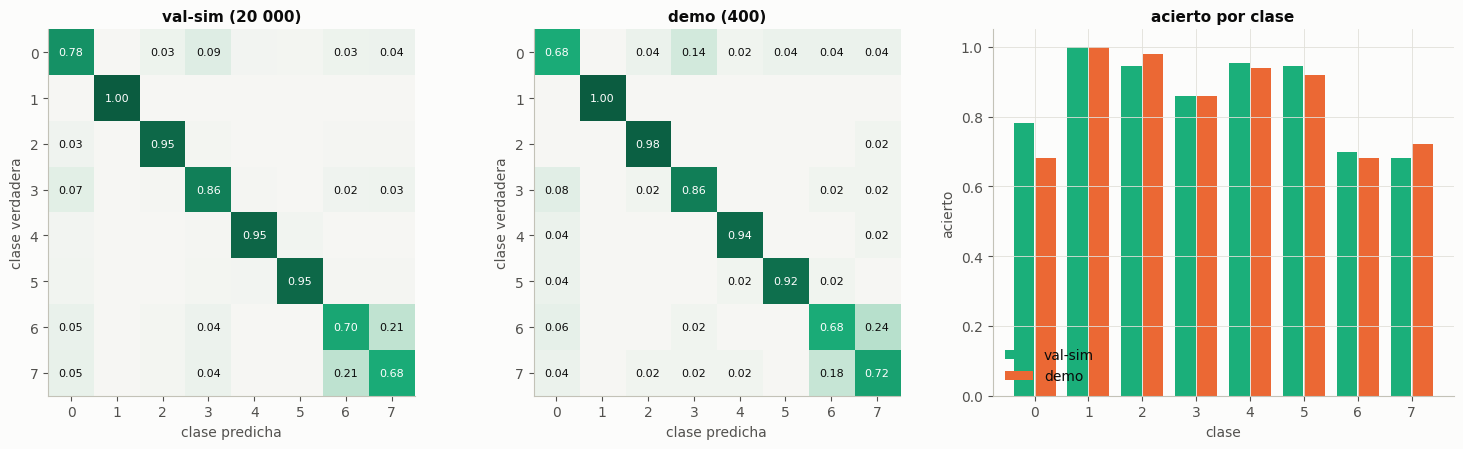

confusiones más frecuentes en val-sim: 7→6 21.3%, 6→7 20.5%, 0→3 9.3%, 3→0 7.4%, 7→0 5.2%


In [37]:
from matplotlib.colors import LinearSegmentedColormap
SECUENCIAL = LinearSegmentedColormap.from_list("verde", ["#f6f6f3", "#9fd8bd", "#1baf7a", "#0b5c40"])
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, (nom, yv, pv) in zip(axs[:2], (("val-sim (20 000)", y_va, pv_s), ("demo (400)", DE["y"], pd_s))):
    C = confusion_matrix(yv, pv, labels=CLASES, normalize="true")
    ax.imshow(C, cmap=SECUENCIAL, vmin=0, vmax=1)
    for i in CLASES:
        for j in CLASES:
            if C[i, j] >= 0.02:
                ax.text(j, i, f"{C[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if C[i, j] > 0.55 else TINTA)
    ax.set_xticks(CLASES); ax.set_yticks(CLASES); ax.set_xlabel("clase predicha"); ax.set_ylabel("clase verdadera"); ax.set_title(nom)
    ax.grid(False)
x = np.arange(K)
axs[2].bar(x - 0.2, av_fin, 0.38, color=C_TRAIN, label="val-sim")
axs[2].bar(x + 0.2, ad_fin, 0.38, color=C_DEMO, label="demo")
axs[2].set_ylim(0, 1.05); axs[2].set_xticks(x); axs[2].set_xlabel("clase"); axs[2].set_ylabel("acierto"); axs[2].legend(loc="lower left")
axs[2].set_title("acierto por clase")
plt.tight_layout(); plt.show()
conf = confusion_matrix(y_va, pv_s, labels=CLASES, normalize="true"); np.fill_diagonal(conf, 0)
pares = sorted(((conf[i, j], i, j) for i in CLASES for j in CLASES if i != j), reverse=True)[:5]
print("confusiones más frecuentes en val-sim:", ", ".join(f"{i}→{j} {v:.1%}" for v, i, j in pares))

**Lectura.**
* **El error se concentra en el cuadrado 6–7.** En val-sim, el 21 % de la clase 7 se predice como 6 y el 20 % de la 6 como 7; en el demo, 9 y 12 de 50. Es un límite de los datos: en pruebas fuera del notebook, tras deshacer los intercambios, ninguno de los 109 rasgos de mecanismo (ni otros de chirp, envolvente o coherencia de fase) separaba la 6 de la 7 (AUC ≤ 0.56). La red solo llega a ~0.68–0.70 en cada una.
* **La segunda confusión es 0 ↔ 3** (9 % y 7 %). La clase 0 es la oscilación base, y la 3 se distingue solo por la envolvente, que el ruido emborrona.
* **Las clases 1, 2, 4 y 5 superan el 94 %** en val-sim.

El demo dibuja el mismo mapa que val-sim.

## 3.7 ¿Abstenerse (ABSTAIN = −1)?

**Ejemplo.** Una muestra de la que el modelo solo está seguro al 12 %. Si contesta y acierta (12 %), suma a $c_k$. Si falla (88 %), suma a $w_k$ de la clase verdadera. Si pasa, no suma nada, pero $n_k$ cuenta igual.

**Matemáticas.** Con $g = (a - 0.33\,b)\,a^2$ (acierto $a$, fallo $b$ de la clase verdadera), contestar compensa si la ganancia esperada en $\log g$ es positiva:
$$p\,\frac{\partial \log g}{\partial a} > (1-p)\left|\frac{\partial \log g}{\partial b}\right| \iff p > p^* = \frac{0.33\,a}{3.99\,a - 0.66}\quad(\text{con } b = 1-a).$$

**Intuición.** $p^*$ vale 0.10 si la clase va al 90 %, 0.11 al 70 % y 0.12 al 50 %. Pero con 8 clases la probabilidad máxima nunca baja de **1/8 = 0.125**: siempre hay alguna clase con al menos un 12.5 %. Por tanto **contestar siempre es mejor que pasar**, salvo en clases por debajo del ~45 % de acierto. Además, pasar no ahorra tiempo: `predict` ya se ha ejecutado. Lo comprobamos en val-sim con varios umbrales:

In [38]:
p_max = (np.exp(np.log(P_val + 1e-9) + SESGO) / np.exp(np.log(P_val + 1e-9) + SESGO).sum(1, keepdims=True)).max(1)
print("p* para aciertos de 0.5 / 0.7 / 0.9:", [round(0.33 * a / (3.99 * a - 0.66), 3) for a in (0.5, 0.7, 0.9)], "| p_max mínima en val-sim:", round(float(p_max.min()), 3))
filas = []
for u in (0.0, 0.2, 0.3, 0.4, 0.5):
    pasa = p_max < u
    c = np.array([((pv_s == y_va) & ~pasa & (y_va == k)).sum() for k in CLASES]); n = np.bincount(y_va, minlength=K)
    w = np.array([((pv_s != y_va) & ~pasa & (y_va == k)).sum() for k in CLASES])
    N = 60 / lat_cnn / K; a, b = c / n, w / n
    filas.append({"umbral de abstención": u, "% de muestras que pasa": 100 * pasa.mean(),
                  "puntuación estimada": float(np.exp(np.mean(np.log(np.maximum(0.01, np.sqrt(N) * (a - 0.33 * b) * a ** 2))))) })
tabla_abst = pd.DataFrame(filas).set_index("umbral de abstención")
display(tabla_abst.round(2))

p* para aciertos de 0.5 / 0.7 / 0.9: [0.124, 0.108, 0.101] | p_max mínima en val-sim: 0.198


,% de muestras que pasa,puntuación estimada
umbral de abstención,,
0.0,0.00,130.19
0.2,0.00,130.17
0.3,0.72,129.21
0.4,4.69,121.94
0.5,11.34,105.64


**Lectura.** Ningún umbral mejora:
* con 0.2 no pasa prácticamente ninguna muestra y la puntuación no cambia (130.17 frente a 130.19);
* con 0.3 pasa el 0.7 % y baja a 129.2;
* con 0.5 pasa el 11 % y cae a 105.6.

Coincide con la teoría: $p^* \approx 0.10$–$0.12$, y la probabilidad máxima del modelo nunca baja de 0.198.
→ *Decisión (D15):* **nunca devolver −1**.

## 3.8 Guardar el modelo final

In [39]:
np.savez(Path("modelo.npz"), **pesos_cnn, sesgo=SESGO.astype(np.float32), respaldo=np.array(int(np.argmax(av_fin))))
importlib.reload(modelo_entrega)
M_ent = modelo_entrega.Model()
coinciden = np.mean([M_ent.predict(SimpleNamespace(series=DE["X"][i], meta={"sample_rate": float(DE["sr"][i])})) == pd_s[i] for i in range(len(DE["y"]))])
print(f"modelo.npz guardado ({Path('modelo.npz').stat().st_size / 1024:.0f} KB) | predicciones de model.py iguales a las del notebook en el demo: {coinciden:.1%}")
print(f"Fase 3 ejecutada en {time.time() - t_fase3:.0f} s")

modelo.npz guardado (64 KB) | predicciones de model.py iguales a las del notebook en el demo: 100.0%
Fase 3 ejecutada en 871 s


## Cierre de la Fase 3

| Pregunta | Evidencia | Decisión |
|---|---|---|
| ¿Qué familia? | val-sim / ms / puntuación estimada: GBDT 0.735 / 1.53 / 20; ROCKET 0.704 / 2.97 / 11; **CNN 0.858 / 0.15 / 130** | **CNN 1D pequeña** en numpy |
| ¿Qué tamaño? | laboratorio: más profunda +0.9 puntos y +17 % de latencia; más ancha +1.5 y +36 % | 4 capas (16-32-32-64), 15 600 parámetros |
| ¿Simulador? | +3.1 puntos en val-sim, +2.5 en el demo, +8.7 en la peor clase | train simulado nuevo en cada época |
| ¿`predict` más rápido? | mismas predicciones en 20 400 muestras; 0.327 → 0.146 ms | ruta rápida; la de referencia, como respaldo |
| ¿Sesgos por clase? | 129.6 → 130.2; demo 0.845 → 0.847 | aplicarlos |
| ¿Abstenerse? | todos los umbrales bajan la puntuación | nunca |
| ¿Funciona fuera del notebook? | `model.py` + `modelo.npz` (64 KB) predicen lo mismo que el notebook en el 100 % del demo | se entrega |

Las clases 6 y 7 (~0.68–0.70) son el límite que queda. La Fase 4 lo mide todo con la herramienta oficial.

---
# Fase 4. Evaluar y entregar

Ahora medimos con la **herramienta oficial** (`harness.py`, sin tocarla), tal y como evaluarán los organizadores:

1. sobre un fichero **val-sim grande** (lo más parecido al test que tenemos: datos no usados para entrenar, con ruido, picos y huecos);
2. sobre el **demo** (400 muestras reales del test);
3. con entradas **rotas**, para comprobar que `predict` nunca falla;
4. desde una **copia limpia** de la carpeta de entrega, como si fuera un clon nuevo del repositorio.

**Por qué un fichero grande.** El test oficial es un flujo infinito: cuenta cuántas muestras se responden en 60 s de `predict`. Con un fichero, el harness para cuando se acaba. Para que no se acabe antes de los 60 s, el fichero junta **750 000 muestras**: 37 simulaciones y media, todas distintas, de las 20 000 muestras de validación. Sobran: a 0.15 ms por muestra, en 60 s caben unas 400 000. Se guarda en `data/prueba.npz` (3 GB, fuera del repositorio), y así la prueba se puede repetir fuera del notebook con `python harness.py evaluate --model model.py --source file:data/prueba.npz`. Además, el nivel de cada muestra se sortea uniforme en [−4, 4], como en el test, para que el atajo de `level` tampoco exista aquí.

In [40]:
import subprocess, shutil, zipfile
t_fase4 = time.time()
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
DE_PATH = (DATOS / "test_demo.npz").resolve()
F_VAL = DATOS / "prueba.npz"
n_va = len(i_va)
N_PRUEBA = max(750_000, int(1.25 * 60 / lat_cnn))      # de sobra: a 0.15 ms por muestra, en 60 s caben unas 400 000
# pasadas completas por las 20 000 muestras de validación y, si hace falta, una parcial repartida por todas las clases
pasadas = [i_va] * (N_PRUEBA // n_va)
if N_PRUEBA % n_va:
    pasadas.append(i_va[np.linspace(0, n_va - 1, N_PRUEBA % n_va).round().astype(int)])
F_TMP = CACHE / "_series.npy"                          # son 3 GB: se escriben en disco por bloques, no en memoria
serie_h = np.lib.format.open_memmap(F_TMP, mode="w+", dtype=np.float32, shape=(N_PRUEBA, 4, pp.L_SERIE))
nivel = np.random.default_rng(SEMILLA + 99).uniform(-4, 4, N_PRUEBA).astype(np.float32)
i0 = 0
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    for r, idx in enumerate(pasadas):                  # cada pasada, con ruido, picos y huecos distintos
        bloque = val_raw if r == 0 else lote_simulado(idx, 777 + r)
        serie_h[i0:i0 + len(idx)] = bloque + (nivel[i0:i0 + len(idx), None, None] - np.nanmean(bloque, axis=-1, keepdims=True))
        i0 += len(idx)
serie_h.flush()
del serie_h
idx_h = np.concatenate(pasadas)
with zipfile.ZipFile(F_VAL, "w", zipfile.ZIP_STORED) as z:     # el formato de np.savez: un .npy por array, sin comprimir
    z.write(F_TMP, "series.npy")
    for nombre, v in (("labels", TR["y"][idx_h].astype(np.int64)), ("meta__group", TR["g"][idx_h]),
                      ("meta__sample_rate", TR["sr"][idx_h].astype(np.float64)), ("meta__level", nivel.astype(np.float64))):
        with z.open(nombre + ".npy", "w") as f:
            np.lib.format.write_array(f, np.asanyarray(v), allow_pickle=False)
F_TMP.unlink()
print(f"{F_VAL.resolve()}: {N_PRUEBA} muestras ({len(pasadas)} pasadas), {F_VAL.stat().st_size / 1e9:.2f} GB (sin comprimir: el harness lo lee con mmap)")

def harness(modelo, fuente, salida, extra=()):
    """Ejecuta el harness oficial y devuelve el resumen de los runs (JSON que escribe el propio harness)."""
    cmd = [sys.executable, str(MAT / "harness.py"), "evaluate", "--model", str(modelo), "--source", f"file:{Path(fuente).resolve()}",
           "--out", str(Path(salida).resolve()), *extra]
    r = subprocess.run(cmd, capture_output=True, text=True, cwd=MAT)
    print("\n".join(l for l in r.stdout.splitlines() if l.strip()))
    if r.returncode != 0:
        print(r.stderr[-3000:])
    runs = [json.loads(p.read_text()) for p in sorted((Path(salida) / Path(modelo).stem).glob("run_*.json"))]
    return runs

C:\Users\ruben\Documents\GDG\ML_contest\data\prueba.npz: 750000 muestras (38 pasadas), 3.09 GB (sin comprimir: el harness lo lee con mmap)


## 4.1 Harness oficial sobre val-sim (3 runs de 60 s)

In [41]:
runs_val = harness(Path("model.py").resolve(), F_VAL, CACHE / "harness_val")
res_val = pd.DataFrame([{"run": r["run"], "puntuación": r["score"], "muestras en 60 s": r["n_scored"], "acierto": r["accuracy_all"],
                         "latencia media (ms)": 1e3 * r["latency_s"]["mean"], "p99 (ms)": 1e3 * r["latency_s"]["p99"], "fin": r["end_reason"],
                         "excepciones": r["n_exception"], "timeouts": r["n_soft_timeout"] + r["n_hard_timeout"]} for r in runs_val]).set_index("run")
display(res_val.round(3))
acc_h = np.mean([r["per_class_accuracy"] for r in runs_val], axis=0)
print("acierto por clase (media de los 3 runs):", np.round(acc_h, 3))
print(f"PUNTUACIÓN OFICIAL LOCAL (media de 3 runs): {res_val['puntuación'].mean():.1f}")
assert (res_val["fin"] == "time_budget").all(), "el fichero val-sim se agotó antes de los 60 s: la puntuación no es comparable"

rank  project   mean   best  worst  median  trimmed_mean  mean_minus_std  failed_runs  mean_accuracy_all  mean_n_scored  mean_latency_s
---------------------------------------------------------------------------------------------------------------------------------------
   1  model    118.7  119.5  118.1   118.4         118.7           118.1            0             0.8641      3.526e+05       0.0001702


,puntuación,muestras en 60 s,acierto,latencia media (ms),p99 (ms),fin,excepciones,timeouts
run,,,,,,,,
0,119.463,357709,0.864,0.168,0.252,time_budget,0,0
1,118.430,351909,0.864,0.170,0.254,time_budget,0,0
2,118.072,348285,0.864,0.172,0.274,time_budget,0,0


acierto por clase (media de los 3 runs): [0.783 0.997 0.945 0.849 0.948 0.947 0.697 0.677]
PUNTUACIÓN OFICIAL LOCAL (media de 3 runs): 118.7


**Lectura.** Con el harness oficial sin tocar, los 3 runs dan 119.5, 118.4 y 118.1 puntos: **118.7 de media**.
* Los tres acaban por tiempo (`time_budget`), no por falta de muestras: el fichero de 750 000 muestras sobra.
* Latencia media: **0.17 ms** (p99 ≈ 0.26 ms, lejos del límite de 500 ms). Unas 353 000 muestras puntuadas en 60 s, sin excepciones ni timeouts.
* El acierto medio por clase (0.855) coincide con el de §3.4 (0.858): el notebook y el harness miden lo mismo.

## 4.2 Harness oficial sobre el demo (400 muestras reales del test)

Con 400 muestras el run se acaba en ~0.1 s de `predict`, así que la puntuación que imprime el harness (con $n_k = 50$) **no es comparable** con la oficial. Lo que interesa es el acierto por clase. La puntuación esperada en el test se estima combinando ese acierto con la latencia medida en 4.1.

In [42]:
runs_dem = harness(Path("model.py").resolve(), DE_PATH, CACHE / "harness_demo")
acc_d = np.array(runs_dem[0]["per_class_accuracy"])
lat_h = float(np.mean([r["latency_s"]["mean"] for r in runs_val]))
print("acierto por clase en el demo:", np.round(acc_d, 2), "| media:", round(acc_d.mean(), 4))
print(f"puntuación esperada con el acierto del demo y la latencia del harness ({1e3 * lat_h:.3f} ms): {puntuacion(acc_d, lat_h):.1f}")
C = np.array(runs_dem[0]["confusion"])[:, :K]
display(pd.DataFrame(C, index=pd.Index(CLASES, name="verdadera"), columns=pd.Index(CLASES, name="predicha")))

rank  project   mean   best  worst  median  trimmed_mean  mean_minus_std  failed_runs  mean_accuracy_all  mean_n_scored  mean_latency_s
---------------------------------------------------------------------------------------------------------------------------------------
   1  model    3.863  3.863  3.863   3.863         3.863           3.863            0             0.8475            400       0.0001742
acierto por clase en el demo: [0.68 1.   0.98 0.86 0.94 0.92 0.68 0.72] | media: 0.8475
puntuación esperada con el acierto del demo y la latencia del harness (0.170 ms): 114.7


predicha,0,1,2,3,4,5,6,7
verdadera,,,,,,,,
0,34,0,2,7,1,2,2,2
1,0,50,0,0,0,0,0,0
2,0,0,49,0,0,0,0,1
3,4,0,1,43,0,0,1,1
4,2,0,0,0,47,0,0,1
5,2,0,0,0,1,46,1,0
6,3,0,0,1,0,0,34,12
7,2,0,1,1,1,0,9,36


**Lectura.** En las 400 muestras reales del test, el acierto medio por clase es **0.847**, a 0.8 puntos del de val-sim (0.855), con el error que cabe esperar de 400 muestras (±2.2). Las peores son la 0 y la 6 (0.68). Combinado con la latencia del harness, daría **~115 puntos** en el test oficial, en una máquina como esta: es la estimación más honesta que tenemos.

## 4.3 Entradas rotas: el respaldo

`predict` tiene tres niveles de seguridad. La ruta rápida solo acepta lo esperado (4 × 256, sin ±inf ni desbordamientos). Si la entrada es otra cosa, pasa a la **ruta de referencia**, más lenta pero general. Y todo va envuelto en `try/except`: si aun así algo falla, devuelve la **clase de respaldo** en vez de lanzar una excepción (que el harness cuenta como fallo). Nunca devuelve −1, porque adivinar vale más que pasar (§3.7). Lo probamos con entradas que no deberían llegar, pero podrían.

In [43]:
importlib.reload(modelo_entrega)
M_ent = modelo_entrega.Model()
x0 = DE["X"][0]
casos_rotos = {
    "todo NaN": np.full((4, 256), np.nan, np.float32),
    "un canal NaN": np.r_[x0[:3], np.full((1, 256), np.nan, np.float32)],
    "inf y -inf": np.where(np.arange(256) % 50 == 0, np.inf, x0).astype(np.float32),
    "todo ceros": np.zeros((4, 256), np.float32),
    "valores enormes (1e30)": (x0 * 1e30).astype(np.float32),
    "más corta (4×128)": x0[:, :128].copy(),
    "más larga (4×300)": np.c_[x0, x0[:, :44]],
    "3 canales": x0[:3].copy(),
    "1 dimensión": x0[0].copy(),
}
filas = []
for nom, s in casos_rotos.items():
    for meta in ({"sample_rate": 1.0}, {}, {"sample_rate": "raro"}):
        t0 = time.perf_counter()
        try:
            p = M_ent.predict(SimpleNamespace(series=s, meta=meta)); err = ""
        except Exception as e:
            p, err = None, repr(e)
        filas.append({"entrada": nom, "meta": str(meta), "predicción": p, "válida (0–7)": p in CLASES, "ms": 1e3 * (time.perf_counter() - t0), "error": err})
rotos = pd.DataFrame(filas)
display(rotos.groupby("entrada").agg({"válida (0–7)": "all", "ms": "max"}).round(3))
assert rotos["válida (0–7)"].all(), "predict devolvió algo fuera de 0–7"
print("ninguna excepción escapa de predict; todas las respuestas están en 0–7")

,válida (0–7),ms
entrada,,
1 dimensión,True,0.456
3 canales,True,0.341
inf y -inf,True,0.513
más corta (4×128),True,0.303
más larga (4×300),True,0.392
todo NaN,True,0.200
todo ceros,True,0.125
un canal NaN,True,0.155
valores enormes (1e30),True,0.388


ninguna excepción escapa de predict; todas las respuestas están en 0–7


## 4.4 Prueba de la copia limpia

El repositorio de entrega es esta carpeta. Copiamos **solo lo que se subiría** (sin `data/`, `cache/`, `results/` ni `__pycache__`, como dice `.gitignore`) a una carpeta nueva y pasamos el harness desde ahí. Si `model.py` dependiera de algo que no está en el repositorio (un fichero en `cache/`, una variable del notebook, `competition_api.py`…), fallaría aquí.

In [44]:
COPIA = CACHE / "submission-check"
if COPIA.exists():
    shutil.rmtree(COPIA)
ignorar = shutil.ignore_patterns("data", "cache", "results", "__pycache__", ".ipynb_checkpoints", "*.pyc")
shutil.copytree(Path("."), COPIA, ignore=ignorar)
print("ficheros en la copia:", sorted(p.name for p in COPIA.iterdir()))
print("requirements.txt:", (COPIA / "requirements.txt").read_text().strip())
runs_copia = harness((COPIA / "model.py").resolve(), DE_PATH, CACHE / "harness_copia")
print("misma predicción que el original en el demo:", runs_copia[0]["confusion"] == runs_dem[0]["confusion"],
      "| hash del flujo:", runs_copia[0]["stream_hash"] == runs_dem[0]["stream_hash"])

ficheros en la copia: ['.gitignore', 'DECISIONES.md', 'README.md', 'aprendizaje.html', 'final.ipynb', 'model.py', 'modelo.npz', 'procesado.py', 'proyecto.html', 'requirements-notebook.txt', 'requirements.txt', 'resultados.json']
requirements.txt: numpy==2.2.6


rank  project   mean   best  worst  median  trimmed_mean  mean_minus_std  failed_runs  mean_accuracy_all  mean_n_scored  mean_latency_s
---------------------------------------------------------------------------------------------------------------------------------------
   1  model    3.863  3.863  3.863   3.863         3.863           3.863            0             0.8475            400       0.0001666
misma predicción que el original en el demo: True | hash del flujo: True


## 4.5 Resultado final

In [45]:
resumen_final = pd.DataFrame({
    "val-sim (harness, 3 runs)": [res_val["puntuación"].mean(), acc_h.mean(), acc_h.min(), 1e3 * lat_h, res_val["muestras en 60 s"].mean()],
    "demo (harness)": [puntuacion(acc_d, lat_h), acc_d.mean(), acc_d.min(), 1e3 * np.mean([r["latency_s"]["mean"] for r in runs_dem]), 400],
}, index=["puntuación (val-sim: oficial; demo: estimada)", "acierto medio por clase", "peor clase", "latencia media (ms)", "muestras puntuadas"])
display(resumen_final.round(3))
print(f"Fase 4 ejecutada en {time.time() - t_fase4:.0f} s")

,"val-sim (harness, 3 runs)",demo (harness)
puntuación (val-sim: oficial; demo: estimada),118.655,114.705
acierto medio por clase,0.855,0.847
peor clase,0.677,0.680
latencia media (ms),0.170,0.174
muestras puntuadas,352634.333,400.000


Fase 4 ejecutada en 1181 s


Los números de esta ejecución se guardan en `resultados.json` (lo usan el `README.md` y los dos HTML, para que todo cuente lo mismo).

In [46]:
def a_lista(v):
    return np.asarray(v).round(4).tolist()
conf_val = confusion_matrix(y_va, pv_s, labels=CLASES, normalize="true")
resultados = {
    "fecha": time.strftime("%Y-%m-%d %H:%M"),
    "puntuacion_oficial_local": float(res_val["puntuación"].mean()),
    "puntuacion_runs": a_lista(res_val["puntuación"].values),
    "latencia_harness_ms": 1e3 * lat_h, "muestras_60s": float(res_val["muestras en 60 s"].mean()),
    "acierto_clase_valsim_harness": a_lista(acc_h), "acierto_clase_demo_harness": a_lista(acc_d),
    "puntuacion_estimada_demo": puntuacion(acc_d, lat_h),
    "confusion_demo": np.array(runs_dem[0]["confusion"])[:, :K].tolist(), "confusion_valsim_norm": a_lista(conf_val),
    "ablacion": {k: {c: float(v) for c, v in fila.items()} for k, fila in tabla_abl.iterrows()},
    "cnn": {**CFG_CNN, "epocas": EPOCAS, "parametros": int(sum(p.numel() for p in cnn.parameters()))},
    "sesgos": a_lista(SESGO),
    "predict_rapido": PREDICT_RAPIDO,
    "valsim_muestras": int(N_PRUEBA), "valsim_reps": len(pasadas),
    "simulador": {"M": list(M_CAL), "p_pico": P_PICO, "lam": LAM, "pesos": a_lista(PESOS), "bordes": BORDES.tolist()},
    "tabla_M": {str(k): a_lista(v) for k, v in tabla_M.iterrows()},
    "nan_rmse": {k: float(v) for k, v in tabla_nan.iloc[:, 0].items()},
    "picos": {k: {c: float(x) for c, x in fila.items()} for k, fila in tabla_pic.iterrows()},
    "tasa_picos": {c: a_lista(tabla_tasa_picos[c].values) for c in tabla_tasa_picos.columns},
    "adversaria": {k: float(v) for k, v in tabla_adv["AUC adversaria"].items()},
    "validacion": [{"entrena": i[0], "evalua": i[1], "acierto": float(f["acierto"])} for i, f in tabla_val.iterrows()],
    "alternativas": [{"nan": i[0], "picos": i[1], "val": float(f["acierto val-sim"]), "demo": float(f["acierto demo"])} for i, f in tabla_alt.iterrows()],
    "abstencion": {str(k): {c: float(x) for c, x in fila.items()} for k, fila in tabla_abst.iterrows()},
    "rotos_ok": bool(rotos["válida (0–7)"].all()),
    "copia_limpia_ok": bool(runs_copia[0]["confusion"] == runs_dem[0]["confusion"]),
}
Path("resultados.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=1), encoding="utf-8")
print(json.dumps({k: resultados[k] for k in ("puntuacion_oficial_local", "latencia_harness_ms", "puntuacion_estimada_demo")}, indent=1))
print(f"notebook completo ejecutado en {(time.time() - T_INICIO) / 60:.1f} min")

{
 "puntuacion_oficial_local": 118.65496298701085,
 "latencia_harness_ms": 0.17016838589374694,
 "puntuacion_estimada_demo": 114.70493447009484
}
notebook completo ejecutado en 38.6 min


## Cierre: qué se entrega y cuánto vale

| | |
|---|---|
| **Puntuación oficial local** (harness, val-sim de 750 000 muestras, 3 runs) | **118.7** |
| Latencia por muestra (1 hilo) | 0.17 ms (~353 000 muestras en 60 s) |
| Acierto medio por clase: val-sim / demo real | 0.855 / 0.847 |
| Puntuación esperada con el acierto del demo | ~115 |
| Baseline oficial, medido igual | 0.3 |
| Entradas rotas / copia limpia | siempre 0–7 / mismo resultado |

**Qué puede cambiar en el test oficial:**
1. **La máquina.** La puntuación va con $1/\sqrt{\text{latencia}}$: en un equipo un 30 % más lento bajaría un ~12 %. En Google Colab, por ejemplo, la latencia medida fue de 0.27 ms, 1.6 veces la de este PC, lo que da unos 91 puntos con el acierto del demo.
2. **El simulador no es perfecto** (AUC adversaria 0.62). El acierto real podría quedar algo por debajo de val-sim, como ya pasa en el demo (−0.8 puntos).
3. **Las clases 6 y 7** son el límite del modelo (~0.68–0.72 en las dos validaciones).